In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/berkerisen/wind-turbine-scada-dataset/T1.csv


In [2]:
df = pd.read_csv(
    "/kaggle/input/datasets/berkerisen/wind-turbine-scada-dataset/T1.csv"
)

print(df)

              Date/Time  LV ActivePower (kW)  Wind Speed (m/s)  \
0      01 01 2018 00:00           380.047791          5.311336   
1      01 01 2018 00:10           453.769196          5.672167   
2      01 01 2018 00:20           306.376587          5.216037   
3      01 01 2018 00:30           419.645905          5.659674   
4      01 01 2018 00:40           380.650696          5.577941   
...                 ...                  ...               ...   
50525  31 12 2018 23:10          2963.980957         11.404030   
50526  31 12 2018 23:20          1684.353027          7.332648   
50527  31 12 2018 23:30          2201.106934          8.435358   
50528  31 12 2018 23:40          2515.694092          9.421366   
50529  31 12 2018 23:50          2820.466064          9.979332   

       Theoretical_Power_Curve (KWh)  Wind Direction (°)  
0                         416.328908          259.994904  
1                         519.917511          268.641113  
2                         390.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50530 entries, 0 to 50529
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Date/Time                      50530 non-null  object 
 1   LV ActivePower (kW)            50530 non-null  float64
 2   Wind Speed (m/s)               50530 non-null  float64
 3   Theoretical_Power_Curve (KWh)  50530 non-null  float64
 4   Wind Direction (°)             50530 non-null  float64
dtypes: float64(4), object(1)
memory usage: 1.9+ MB


In [4]:
df['Date/Time'] = pd.to_datetime(
    df['Date/Time'],
    format='%d %m %Y %H:%M'
)

In [5]:
df['Date/Time'] = pd.to_datetime(df['Date/Time'])

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50530 entries, 0 to 50529
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Date/Time                      50530 non-null  datetime64[ns]
 1   LV ActivePower (kW)            50530 non-null  float64       
 2   Wind Speed (m/s)               50530 non-null  float64       
 3   Theoretical_Power_Curve (KWh)  50530 non-null  float64       
 4   Wind Direction (°)             50530 non-null  float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 1.9 MB


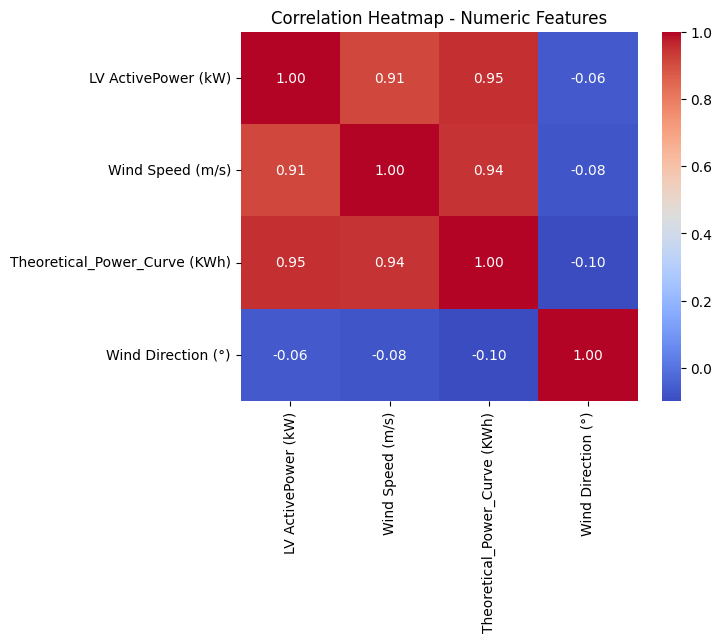

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_df = df.select_dtypes(include='number')

corr = numeric_df.corr()

#plt.figure(figsize=(10, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap - Numeric Features')
plt.show()

In [8]:
df.head()

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
0,2018-01-01 00:00:00,380.047791,5.311336,416.328908,259.994904
1,2018-01-01 00:10:00,453.769196,5.672167,519.917511,268.641113
2,2018-01-01 00:20:00,306.376587,5.216037,390.900016,272.564789
3,2018-01-01 00:30:00,419.645905,5.659674,516.127569,271.258087
4,2018-01-01 00:40:00,380.650696,5.577941,491.702972,265.674286


In [9]:
"""
The data's in the file are:

    Date/Time (for 10 minutes intervals)
    LV ActivePower (kW): The power generated by the turbine for that moment
    Wind Speed (m/s): The wind speed at the hub height of the turbine 
            (the wind speed that turbine use for electricity generation)
    Theoretical_Power_Curve (KWh): The theoretical power values that the turbine generates with 
            that wind speed which is given by the turbine manufacturer
    Wind Direction (°): The wind direction at the hub height of the turbine 
            (wind turbines turn to this direction automaticly)

"""
# Renewable Energy

"\nThe data's in the file are:\n\n    Date/Time (for 10 minutes intervals)\n    LV ActivePower (kW): The power generated by the turbine for that moment\n    Wind Speed (m/s): The wind speed at the hub height of the turbine \n            (the wind speed that turbine use for electricity generation)\n    Theoretical_Power_Curve (KWh): The theoretical power values that the turbine generates with \n            that wind speed which is given by the turbine manufacturer\n    Wind Direction (°): The wind direction at the hub height of the turbine \n            (wind turbines turn to this direction automaticly)\n\n"

In [10]:
"""
| Area                       | Library            | Main use                                           |
| -------------------------  | -----------------  | -------------------------------------------------- |
| ☀️ **Solar PV**            | `pvlib`           | PV modeling, solar position, irradiance, PV power  |
| ☀️ **Solar thermal**       | `oemof` / `PySAM` | Solar-energy system modeling                       |
| 🌬️ **Wind**                | `windpowerlib`    | Wind turbine and wind-power calculations           |
| ⚡ **Energy systems**      | `oemof`           | Energy-system modeling and optimization            |
| ⚡ **Energy optimization** | `PyPSA`           | Power systems, renewable integration, optimization |
| ⚡ **Energy optimization** | `Calliope`        | Multi-region energy-system optimization            |
| 💧 **Hydropower**          | `PyPSA`, `oemof`  | Hydropower within energy-system models             |
| 🌡️ **Thermal systems**     | `CoolProp`        | Thermophysical properties                          |
| 🔥 **Heat transfer**       | `ht`              | Heat-transfer calculations                         |
| 🌊 **Fluid systems**       | `fluids`          | Pipe flow, pressure drop, fluid calculations       |
| 📐 **Engineering units**   | `pint`            | Unit conversion/management                         |

"""
#| 🌬️ **Wind**                | `windpowerlib`    | Wind turbine and wind-power calculations           |

'\n| Area                       | Library            | Main use                                           |\n| -------------------------  | -----------------  | -------------------------------------------------- |\n| ☀️ **Solar PV**            | `pvlib`           | PV modeling, solar position, irradiance, PV power  |\n| ☀️ **Solar thermal**       | `oemof` / `PySAM` | Solar-energy system modeling                       |\n| 🌬️ **Wind**                | `windpowerlib`    | Wind turbine and wind-power calculations           |\n| ⚡ **Energy systems**      | `oemof`           | Energy-system modeling and optimization            |\n| ⚡ **Energy optimization** | `PyPSA`           | Power systems, renewable integration, optimization |\n| ⚡ **Energy optimization** | `Calliope`        | Multi-region energy-system optimization            |\n| 💧 **Hydropower**          | `PyPSA`, `oemof`  | Hydropower within energy-system models             |\n| 🌡️ **Thermal systems**     | `CoolProp`        | The

In [11]:
!pip install pint

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 326.5/326.5 kB 6.4 MB/s eta 0:00:00ta 0:00:01


In [12]:
from pint import UnitRegistry

ureg = UnitRegistry()

df['LVActive_Power(W)'] = (
    df['LV ActivePower (kW)'].values * ureg.kilowatt
).to(ureg.watt).magnitude

df['Theoretical_Power(W)'] = (
    df['Theoretical_Power_Curve (KWh)'].values * ureg.kilowatt
).to(ureg.watt).magnitude

df['Wind_Direction(rad)'] = (
    df['Wind Direction (°)'].values * ureg.degree
).to(ureg.radian).magnitude

In [13]:
!pip install windpowerlib 

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 1.8 MB/s eta 0:00:00a 0:00:01


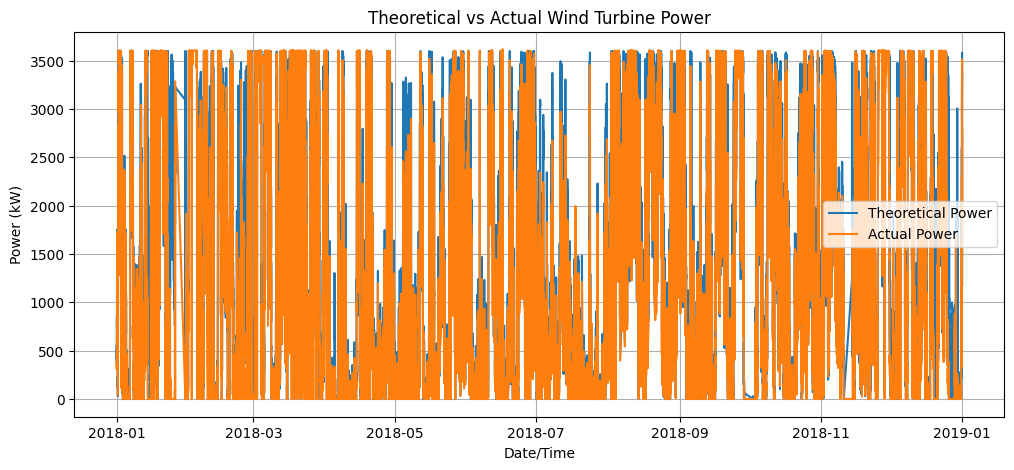

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    df['Date/Time'],
    df['Theoretical_Power_Curve (KWh)'],
    label='Theoretical Power'
)

plt.plot(
    df['Date/Time'],
    df['LV ActivePower (kW)'],
    label='Actual Power'
)

plt.xlabel('Date/Time')
plt.ylabel('Power (kW)')
plt.title('Theoretical vs Actual Wind Turbine Power')
plt.legend()
plt.grid(True)
plt.show()

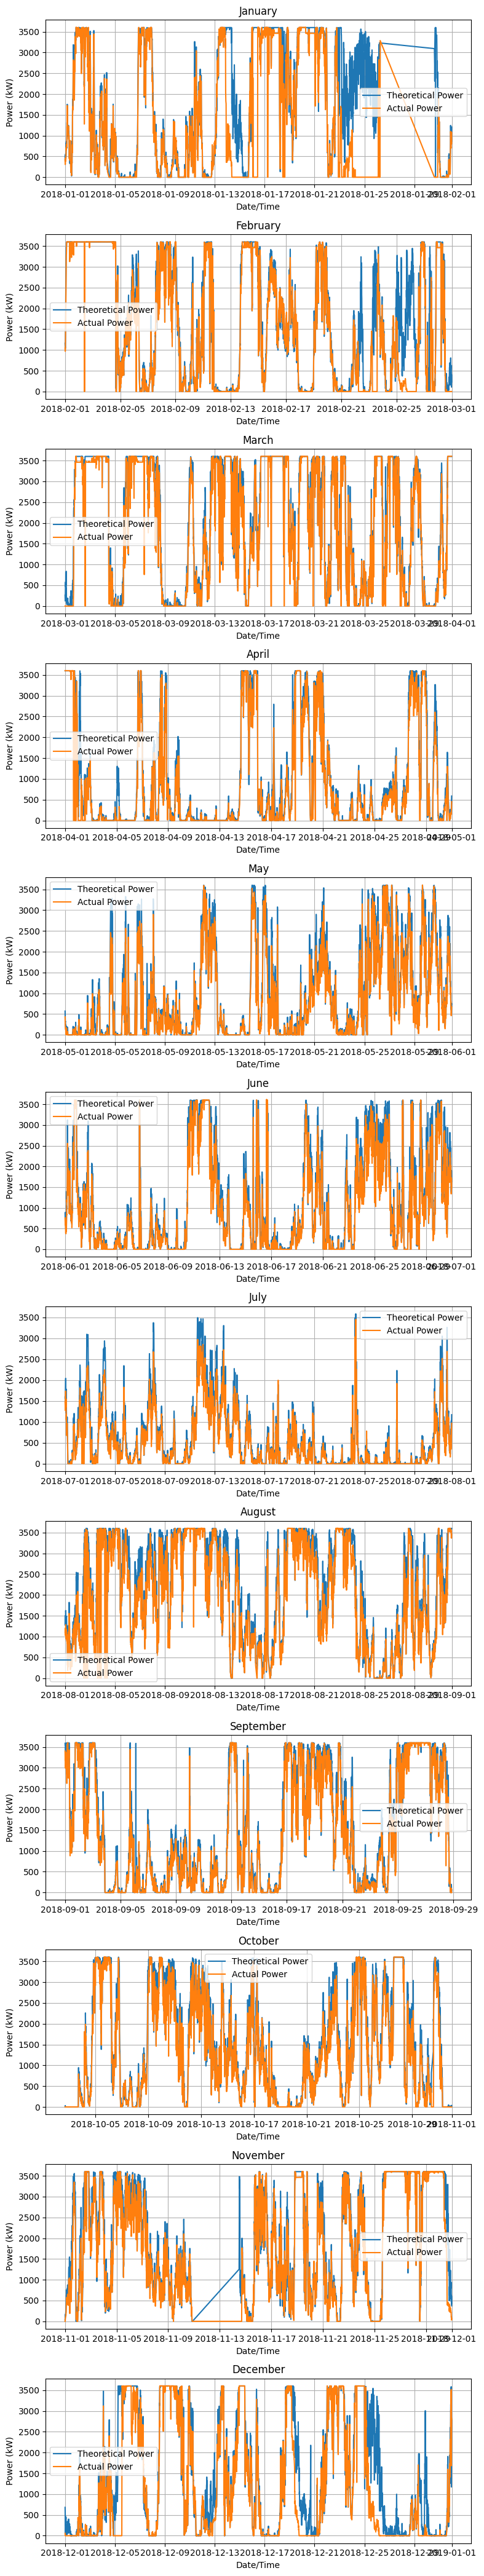

In [15]:
import matplotlib.pyplot as plt

df['Date/Time'] = pd.to_datetime(df['Date/Time'])

#fig, axes = plt.subplots(6, 2, figsize=(16, 24))
fig, axes = plt.subplots(12, 1, figsize=(8, 42))

for month, ax in enumerate(axes.flat, start=1):
    data = df[df['Date/Time'].dt.month == month]

    ax.plot(
        data['Date/Time'],
        data['Theoretical_Power_Curve (KWh)'],
        label='Theoretical Power'
    )

    ax.plot(
        data['Date/Time'],
        data['LV ActivePower (kW)'],
        label='Actual Power'
    )

    ax.set_title(data['Date/Time'].dt.strftime('%B').iloc[0])
    ax.set_xlabel('Date/Time')
    ax.set_ylabel('Power (kW)')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

/tmp/ipykernel_49/3907487499.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  monthly_mse = df.groupby('Month').apply(


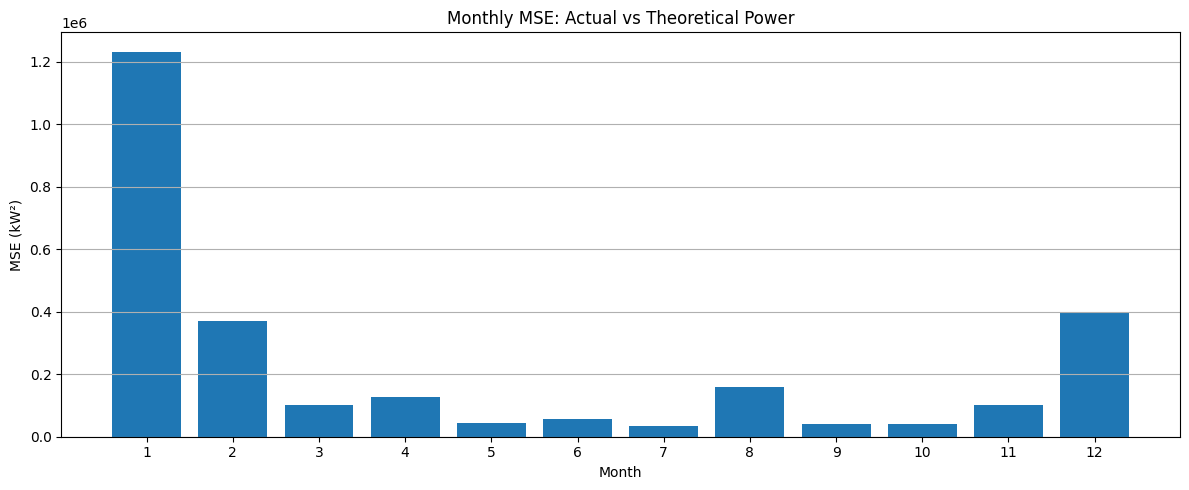

In [16]:
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

df['Month'] = df['Date/Time'].dt.month

monthly_mse = df.groupby('Month').apply(
    lambda x: mean_squared_error(
        x['LV ActivePower (kW)'],
        x['Theoretical_Power_Curve (KWh)']
    )
)

plt.figure(figsize=(12, 5))

plt.bar(monthly_mse.index, monthly_mse.values)

plt.xlabel('Month')
plt.ylabel('MSE (kW²)')
plt.title('Monthly MSE: Actual vs Theoretical Power')
plt.xticks(range(1, 13))
plt.grid(axis='y')

plt.tight_layout()
plt.show()

In [17]:
"""
import numpy as np, pandas as pd, requests, time

URL = "https://archive-api.open-meteo.com/v1/archive"

# UTC hour of every row (local time assumed UTC+3), taken from the dataframe
utc_hour = (df["Date/Time"] - pd.Timedelta(hours=3)).dt.floor("1h")
START = utc_hour.min().strftime("%Y-%m-%d")
END   = utc_hour.max().strftime("%Y-%m-%d")
hours = pd.date_range(START, END + " 23:00", freq="h")

# search grid over Turkey
points = [(round(la, 2), round(lo, 2))
          for la in np.arange(35.5, 42.51, 1.0)
          for lo in np.arange(25.5, 45.01, 1.0)]

def fetch(batch):
    params = {"latitude":  ",".join(str(p[0]) for p in batch),
              "longitude": ",".join(str(p[1]) for p in batch),
              "start_date": START, "end_date": END,
              "hourly": "wind_speed_100m", "wind_speed_unit": "ms",
              "timezone": "UTC"}
    for t in range(6):
        try:
            r = requests.get(URL, params=params, timeout=120)
            if r.status_code == 429:
                time.sleep(20 * (t + 1)); continue
            r.raise_for_status()
            out = r.json()
            return out if isinstance(out, list) else [out]
        except (requests.RequestException, ValueError):
            time.sleep(5 * (t + 1))
    raise RuntimeError("Open-Meteo failed after retries")

# 1) download into one matrix (hours x points)
era_mat = np.full((len(hours), len(points)), np.nan, dtype="float32")
for i in range(0, len(points), 5):
    for j, res in enumerate(fetch(points[i:i + 5])):
        era_mat[:, i + j] = res["hourly"]["wind_speed_100m"]
    time.sleep(1)

# 2) turbine hourly wind aligned to `hours`
scada = df.groupby(utc_hour)["Wind Speed (m/s)"].mean().reindex(hours).to_numpy()
ok = ~np.isnan(scada)

# 3) pick the grid point that follows the turbine best
corr = np.array([np.corrcoef(scada[ok], era_mat[ok, k])[0, 1] for k in range(len(points))])
b = int(np.nanargmax(corr))
LAT, LON = points[b]
print("LAT, LON =", LAT, LON, "| corr =", round(corr[b], 3))

# 4) save latitude and longitude in df (same value in every row, no NaN)
df["Latitude"]  = LAT
df["Longitude"] = LON

# 5) wind for that location -> new columns in df
j = requests.get(URL, params={"latitude": LAT, "longitude": LON,
                              "start_date": START, "end_date": END,
                              "hourly": "wind_speed_100m,wind_direction_100m",
                              "wind_speed_unit": "ms", "timezone": "UTC"},
                 timeout=120).json()["hourly"]
t = pd.to_datetime(j["time"])
df["ERA5_ws100"] = utc_hour.map(pd.Series(j["wind_speed_100m"], index=t))
df["ERA5_wd100"] = utc_hour.map(pd.Series(j["wind_direction_100m"], index=t))

print(df.shape)
print(df[["Date/Time", "Latitude", "Longitude", "ERA5_ws100", "ERA5_wd100"]].isna().sum())
"""

'\nimport numpy as np, pandas as pd, requests, time\n\nURL = "https://archive-api.open-meteo.com/v1/archive"\n\n# UTC hour of every row (local time assumed UTC+3), taken from the dataframe\nutc_hour = (df["Date/Time"] - pd.Timedelta(hours=3)).dt.floor("1h")\nSTART = utc_hour.min().strftime("%Y-%m-%d")\nEND   = utc_hour.max().strftime("%Y-%m-%d")\nhours = pd.date_range(START, END + " 23:00", freq="h")\n\n# search grid over Turkey\npoints = [(round(la, 2), round(lo, 2))\n          for la in np.arange(35.5, 42.51, 1.0)\n          for lo in np.arange(25.5, 45.01, 1.0)]\n\ndef fetch(batch):\n    params = {"latitude":  ",".join(str(p[0]) for p in batch),\n              "longitude": ",".join(str(p[1]) for p in batch),\n              "start_date": START, "end_date": END,\n              "hourly": "wind_speed_100m", "wind_speed_unit": "ms",\n              "timezone": "UTC"}\n    for t in range(6):\n        try:\n            r = requests.get(URL, params=params, timeout=120)\n            if r.stat

In [18]:
df.head()

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°),LVActive_Power(W),Theoretical_Power(W),Wind_Direction(rad),Month
0,2018-01-01 00:00:00,380.047791,5.311336,416.328908,259.994904,380047.790527,416328.907825,4.537767,1
1,2018-01-01 00:10:00,453.769196,5.672167,519.917511,268.641113,453769.195557,519917.511061,4.688672,1
2,2018-01-01 00:20:00,306.376587,5.216037,390.900016,272.564789,306376.586914,390900.015811,4.757153,1
3,2018-01-01 00:30:00,419.645905,5.659674,516.127569,271.258087,419645.904541,516127.568976,4.734347,1
4,2018-01-01 00:40:00,380.650696,5.577941,491.702972,265.674286,380650.695801,491702.971954,4.636891,1


In [19]:
# 2018 Scada Data of a Wind Turbine in Turkey

import numpy as np, pandas as pd, requests, time

URL = "https://archive-api.open-meteo.com/v1/archive"
                  
df["Date/Time"] = pd.to_datetime(df["Date/Time"], format="%d %m %Y %H:%M")
df["Month"] = df["Date/Time"].dt.month
df["LVActive_Power(W)"]    = df["LV ActivePower (kW)"] * 1000
df["Theoretical_Power(W)"] = df["Theoretical_Power_Curve (KWh)"] * 1000
df["Wind_Direction(rad)"]  = np.deg2rad(df["Wind Direction (°)"])
print(df.shape)

# 2) Dates come from df (local time assumed UTC+3)
utc_hour = (df["Date/Time"] - pd.Timedelta(hours=3)).dt.floor("1h")
START = utc_hour.min().strftime("%Y-%m-%d")
END   = utc_hour.max().strftime("%Y-%m-%d")
hours = pd.date_range(START, END + " 23:00", freq="h")

# 3) Search grid over Turkey (160 points)
points = [(round(la, 2), round(lo, 2))
          for la in np.arange(35.5, 42.51, 1.0)
          for lo in np.arange(25.5, 45.01, 1.0)]

def fetch(batch):
    params = {"latitude":  ",".join(str(p[0]) for p in batch),
              "longitude": ",".join(str(p[1]) for p in batch),
              "start_date": START, "end_date": END,
              "hourly": "wind_speed_100m", "wind_speed_unit": "ms",
              "timezone": "UTC"}
    for t in range(6):
        try:
            r = requests.get(URL, params=params, timeout=120)
            if r.status_code == 429:             # rate limit: wait and retry
                time.sleep(20 * (t + 1)); continue
            r.raise_for_status()
            out = r.json()
            return out if isinstance(out, list) else [out]
        except (requests.RequestException, ValueError):   # cut/broken JSON: retry
            time.sleep(5 * (t + 1))
    raise RuntimeError("Open-Meteo failed after retries")

# 4) Download ERA5 wind into one matrix (hours x points)
era_mat = np.full((len(hours), len(points)), np.nan, dtype="float32")
for i in range(0, len(points), 5):
    for j, res in enumerate(fetch(points[i:i + 5])):
        era_mat[:, i + j] = res["hourly"]["wind_speed_100m"]
    time.sleep(1)

# 5) Latitude and longitude per row, saved directly in df
idx = hours.get_indexer(utc_hour)                # row -> hour position in era_mat
ws  = df["Wind Speed (m/s)"].to_numpy(dtype="float32")

diff = np.abs(era_mat[idx] - ws[:, None])        # rows x points
k    = np.argmin(np.nan_to_num(diff, nan=np.inf), axis=1)
pts  = np.array(points)

df["Latitude"]  = pts[k, 0]
df["Longitude"] = pts[k, 1]

print(df.shape)                                  # (50530, 11)
print(df[["Date/Time", "Latitude", "Longitude"]].isna().sum())   # 0 NaN
print(df[["Date/Time", "Wind Speed (m/s)", "Latitude", "Longitude"]].head())

(50530, 9)
(50530, 11)
Date/Time    0
Latitude     0
Longitude    0
dtype: int64
            Date/Time  Wind Speed (m/s)  Latitude  Longitude
0 2018-01-01 00:00:00          5.311336      41.5       38.5
1 2018-01-01 00:10:00          5.672167      42.5       27.5
2 2018-01-01 00:20:00          5.216037      42.5       28.5
3 2018-01-01 00:30:00          5.659674      42.5       27.5
4 2018-01-01 00:40:00          5.577941      35.5       41.5


In [20]:
df['Latitude'].unique()

array([41.5, 42.5, 35.5, 40.5, 38.5, 36.5, 37.5, 39.5])

In [21]:
df['Longitude'].unique()

array([38.5, 27.5, 28.5, 41.5, 39.5, 25.5, 33.5, 29.5, 32.5, 44.5, 31.5,
       37.5, 34.5, 42.5, 40.5, 43.5, 30.5, 36.5, 35.5, 26.5])

In [22]:
df[['Latitude','Longitude']].value_counts()

Latitude  Longitude
39.5      25.5         1762
38.5      25.5          989
37.5      25.5          936
42.5      29.5          880
40.5      28.5          842
                       ... 
39.5      38.5          112
41.5      42.5          112
          41.5          111
42.5      44.5           99
40.5      41.5           92
Name: count, Length: 160, dtype: int64

In [23]:
df

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°),LVActive_Power(W),Theoretical_Power(W),Wind_Direction(rad),Month,Latitude,Longitude
0,2018-01-01 00:00:00,380.047791,5.311336,416.328908,259.994904,3.800478e+05,4.163289e+05,4.537767,1,41.5,38.5
1,2018-01-01 00:10:00,453.769196,5.672167,519.917511,268.641113,4.537692e+05,5.199175e+05,4.688672,1,42.5,27.5
2,2018-01-01 00:20:00,306.376587,5.216037,390.900016,272.564789,3.063766e+05,3.909000e+05,4.757153,1,42.5,28.5
3,2018-01-01 00:30:00,419.645905,5.659674,516.127569,271.258087,4.196459e+05,5.161276e+05,4.734347,1,42.5,27.5
4,2018-01-01 00:40:00,380.650696,5.577941,491.702972,265.674286,3.806507e+05,4.917030e+05,4.636891,1,35.5,41.5
...,...,...,...,...,...,...,...,...,...,...,...
50525,2018-12-31 23:10:00,2963.980957,11.404030,3397.190793,80.502724,2.963981e+06,3.397191e+06,1.405038,12,36.5,25.5
50526,2018-12-31 23:20:00,1684.353027,7.332648,1173.055771,84.062599,1.684353e+06,1.173056e+06,1.467169,12,40.5,29.5
50527,2018-12-31 23:30:00,2201.106934,8.435358,1788.284755,84.742500,2.201107e+06,1.788285e+06,1.479036,12,40.5,28.5
50528,2018-12-31 23:40:00,2515.694092,9.421366,2418.382503,84.297913,2.515694e+06,2.418383e+06,1.471276,12,40.5,26.5


In [24]:
VARS = ["wind_speed_100m", "temperature_2m", "surface_pressure"]

def fetch(batch):
    params = {"latitude":  ",".join(str(p[0]) for p in batch),
              "longitude": ",".join(str(p[1]) for p in batch),
              "start_date": START, "end_date": END,
              "hourly": ",".join(VARS), "wind_speed_unit": "ms",
              "timezone": "UTC"}
    for t in range(6):
        try:
            r = requests.get(URL, params=params, timeout=120)
            if r.status_code == 429:
                time.sleep(20 * (t + 1)); continue
            r.raise_for_status()
            out = r.json()
            return out if isinstance(out, list) else [out]
        except (requests.RequestException, ValueError):
            time.sleep(5 * (t + 1))
    raise RuntimeError("Open-Meteo failed after retries")

# 4) download: one matrix (hours x points) per variable
mats = {v: np.full((len(hours), len(points)), np.nan, dtype="float32") for v in VARS}
B = 3                                             # 3 variables -> bigger response, so smaller batches
for i in range(0, len(points), B):
    for j, res in enumerate(fetch(points[i:i + B])):
        for v in VARS:
            mats[v][:, i + j] = res["hourly"][v]
    time.sleep(1)

# 5) per-row latitude / longitude, then temperature and pressure at that same point
idx = hours.get_indexer(utc_hour)
ws  = df["Wind Speed (m/s)"].to_numpy(dtype="float32")

diff = np.abs(mats["wind_speed_100m"][idx] - ws[:, None])
k    = np.argmin(np.nan_to_num(diff, nan=np.inf), axis=1)
pts  = np.array(points)
rows = np.arange(len(df))

df["Latitude"]    = pts[k, 0]
df["Longitude"]   = pts[k, 1]
df["Temperature"] = mats["temperature_2m"][idx, k]      # °C
df["Pressure"]    = mats["surface_pressure"][idx, k]    # hPa

print(df.shape)                                   # (50530, 13)
print(df[["Date/Time", "Latitude", "Longitude", "Temperature", "Pressure"]].isna().sum())
print(df[["Date/Time", "Latitude", "Longitude", "Temperature", "Pressure"]].head())


(50530, 13)
Date/Time      0
Latitude       0
Longitude      0
Temperature    0
Pressure       0
dtype: int64
            Date/Time  Latitude  Longitude  Temperature     Pressure
0 2018-01-01 00:00:00      41.5       38.5         11.6  1015.000000
1 2018-01-01 00:10:00      42.5       27.5          3.2  1018.900024
2 2018-01-01 00:20:00      42.5       28.5          8.3  1018.500000
3 2018-01-01 00:30:00      42.5       27.5          3.2  1018.900024
4 2018-01-01 00:40:00      35.5       41.5         12.2   977.299988


In [25]:
# pip install windpowerlib
import pandas as pd
from windpowerlib import WindTurbine, ModelChain

# 1) turbine: power curve taken from the theoretical curve already in df
pc = (df.assign(ws=df["Wind Speed (m/s)"].round(1))
        .groupby("ws")["Theoretical_Power(W)"].mean()
        .reset_index())
pc.columns = ["wind_speed", "value"]            # m/s, W

turbine = WindTurbine(hub_height=100,            # assumption: 100 m, matches ERA5 wind_speed_100m
                      nominal_power=pc["value"].max(),
                      power_curve=pc)

# 2) weather: columns are (variable, height in m)
weather = pd.DataFrame({
    ("wind_speed", 100):       df["Wind Speed (m/s)"].to_numpy(),
    ("temperature", 2):        df["Temperature"].to_numpy(),     # K
    ("pressure", 0):           df["Pressure"].to_numpy(),        # Pa
    ("roughness_length", 0):   0.1,                              # assumption
}, index=df["Date/Time"])
weather.columns.names = ["variable_name", "height"]

# 3) run
mc = ModelChain(turbine, density_model="ideal_gas").run_model(weather)
df["WPL_Power(W)"] = mc.power_output.to_numpy()

print(df[["LVActive_Power(W)", "Theoretical_Power(W)", "WPL_Power(W)"]].head())

   LVActive_Power(W)  Theoretical_Power(W)   WPL_Power(W)
0      380047.790527         416328.907825  417030.159425
1      453769.195557         519917.511061  520118.372877
2      306376.586914         390900.015811  390627.607355
3      419645.904541         516127.568976  516273.663227
4      380650.695801         491702.971954  491441.476579


In [26]:
df['Latitude'].unique()
#array([41.5, 42.5, 35.5, 40.5, 38.5, 36.5, 37.5, 39.5])

array([41.5, 42.5, 35.5, 40.5, 38.5, 36.5, 37.5, 39.5])

In [27]:
df['Longitude'].unique()
#array([38.5, 27.5, 28.5, 41.5, 39.5, 25.5, 33.5, 29.5, 32.5, 44.5, 31.5,37.5, 34.5, 42.5, 40.5, 43.5, 30.5, 36.5, 35.5, 26.5])

array([38.5, 27.5, 28.5, 41.5, 39.5, 25.5, 33.5, 29.5, 32.5, 44.5, 31.5,
       37.5, 34.5, 42.5, 40.5, 43.5, 30.5, 36.5, 35.5, 26.5])

In [28]:
df.head()

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°),LVActive_Power(W),Theoretical_Power(W),Wind_Direction(rad),Month,Latitude,Longitude,Temperature,Pressure,WPL_Power(W)
0,2018-01-01 00:00:00,380.047791,5.311336,416.328908,259.994904,380047.790527,416328.907825,4.537767,1,41.5,38.5,11.6,1015.000000,417030.159425
1,2018-01-01 00:10:00,453.769196,5.672167,519.917511,268.641113,453769.195557,519917.511061,4.688672,1,42.5,27.5,3.2,1018.900024,520118.372877
2,2018-01-01 00:20:00,306.376587,5.216037,390.900016,272.564789,306376.586914,390900.015811,4.757153,1,42.5,28.5,8.3,1018.500000,390627.607355
3,2018-01-01 00:30:00,419.645905,5.659674,516.127569,271.258087,419645.904541,516127.568976,4.734347,1,42.5,27.5,3.2,1018.900024,516273.663227
4,2018-01-01 00:40:00,380.650696,5.577941,491.702972,265.674286,380650.695801,491702.971954,4.636891,1,35.5,41.5,12.2,977.299988,491441.476579


In [29]:
# pip install pint
import pint
ureg = pint.UnitRegistry()

temp_c = mats["temperature_2m"][idx, k]      # °C
pres_h = mats["surface_pressure"][idx, k]    # hPa

df["Temperature"] = ureg.Quantity(temp_c, ureg.degC).to(ureg.kelvin).magnitude
df["Pressure"]    = ureg.Quantity(pres_h, ureg.hPa).to(ureg.pascal).magnitude

In [30]:
# air density
R = 287.05

df["air_density"] = (
    df["Pressure"] /
    (R * df["Temperature"])
)

In [31]:
df.head()

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°),LVActive_Power(W),Theoretical_Power(W),Wind_Direction(rad),Month,Latitude,Longitude,Temperature,Pressure,WPL_Power(W),air_density
0,2018-01-01 00:00:00,380.047791,5.311336,416.328908,259.994904,380047.790527,416328.907825,4.537767,1,41.5,38.5,284.750000,101500.0,417030.159425,1.241780
1,2018-01-01 00:10:00,453.769196,5.672167,519.917511,268.641113,453769.195557,519917.511061,4.688672,1,42.5,27.5,276.350006,101890.0,520118.372877,1.284442
2,2018-01-01 00:20:00,306.376587,5.216037,390.900016,272.564789,306376.586914,390900.015811,4.757153,1,42.5,28.5,281.449982,101850.0,390627.607355,1.260673
3,2018-01-01 00:30:00,419.645905,5.659674,516.127569,271.258087,419645.904541,516127.568976,4.734347,1,42.5,27.5,276.350006,101890.0,516273.663227,1.284442
4,2018-01-01 00:40:00,380.650696,5.577941,491.702972,265.674286,380650.695801,491702.971954,4.636891,1,35.5,41.5,285.350006,97730.0,491441.476579,1.193143


In [32]:
import numpy as np, pandas as pd
from windpowerlib import WindTurbine, ModelChain

pc = (df.assign(ws=df["Wind Speed (m/s)"].round(1))
        .groupby("ws")["Theoretical_Power(W)"].mean()
        .reset_index())
pc.columns = ["wind_speed", "value"]              # m/s, W
pc = pc.sort_values("wind_speed")

turbine = WindTurbine(hub_height=100,             # assumption, replace with the real value if known
                      nominal_power=pc["value"].max(),
                      power_curve=pc)

In [33]:
weather = pd.DataFrame({
    ("wind_speed", 100):     df["Wind Speed (m/s)"].to_numpy(),   # m/s
    ("temperature", 2):      df["Temperature"].to_numpy(),        # K
    ("pressure", 0):         df["Pressure"].to_numpy(),           # Pa
    ("roughness_length", 0): 0.1,                                 # assumption
}, index=df["Date/Time"])
weather.columns.names = ["variable_name", "height"]

In [34]:
# a) power curve only (needs just wind speed)
mc = ModelChain(turbine).run_model(weather)
df["WPL_Power(W)"] = mc.power_output.to_numpy()

# b) with air-density correction (uses temperature and pressure)
mc2 = ModelChain(turbine, density_model="ideal_gas",
                 density_correction=True).run_model(weather)
df["WPL_Power_dens(W)"] = mc2.power_output.to_numpy()

In [35]:
err = df["WPL_Power_dens(W)"] - df["LVActive_Power(W)"]
print("RMSE (kW):", np.sqrt((err**2).mean()) / 1000)
print("Mean bias (kW):", err.mean() / 1000)

RMSE (kW): 447.2005836148849
Mean bias (kW): 137.97699627310365


In [36]:
df.head()

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°),LVActive_Power(W),Theoretical_Power(W),Wind_Direction(rad),Month,Latitude,Longitude,Temperature,Pressure,WPL_Power(W),air_density,WPL_Power_dens(W)
0,2018-01-01 00:00:00,380.047791,5.311336,416.328908,259.994904,380047.790527,416328.907825,4.537767,1,41.5,38.5,284.750000,101500.0,417030.159425,1.241780,418638.959416
1,2018-01-01 00:10:00,453.769196,5.672167,519.917511,268.641113,453769.195557,519917.511061,4.688672,1,42.5,27.5,276.350006,101890.0,520118.372877,1.284442,541992.422969
2,2018-01-01 00:20:00,306.376587,5.216037,390.900016,272.564789,306376.586914,390900.015811,4.757153,1,42.5,28.5,281.449982,101850.0,390627.607355,1.260673,399663.926132
3,2018-01-01 00:30:00,419.645905,5.659674,516.127569,271.258087,419645.904541,516127.568976,4.734347,1,42.5,27.5,276.350006,101890.0,516273.663227,1.284442,538092.885143
4,2018-01-01 00:40:00,380.650696,5.577941,491.702972,265.674286,380650.695801,491702.971954,4.636891,1,35.5,41.5,285.350006,97730.0,491441.476579,1.193143,471388.425799


In [37]:
"""
from windpowerlib import WindTurbine, ModelChain

# Initialize a standard or custom wind turbine configuration
my_turbine = WindTurbine(
    hub_height=50,  # Matches the 50m metric from the chart
    rotor_diameter=40,
    power_curve=my_custom_power_curve_dataframe # or imported from the OpenEnergy Database
)

# Use ModelChain to compute power outputs over time series weather data
model = ModelChain(my_turbine)
# model.run_model(weather_df)
"""

'\nfrom windpowerlib import WindTurbine, ModelChain\n\n# Initialize a standard or custom wind turbine configuration\nmy_turbine = WindTurbine(\n    hub_height=50,  # Matches the 50m metric from the chart\n    rotor_diameter=40,\n    power_curve=my_custom_power_curve_dataframe # or imported from the OpenEnergy Database\n)\n\n# Use ModelChain to compute power outputs over time series weather data\nmodel = ModelChain(my_turbine)\n# model.run_model(weather_df)\n'

In [38]:
!pip install openmeteo-requests requests-cache retry-requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.8/70.8 kB 1.2 MB/s eta 0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 229.1/229.1 kB 5.3 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 862.2/862.2 kB 18.5 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.3/134.3 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 407.4/407.4 kB 7.8 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 37.6 MB/s eta 0:00:00:00:01
  Attempting uninstall: flatbuffers
    Found existing installation: flatbuffers 25.12.19
    Uninstalling flatbuffers-25.12.19:
      Successfully uninstalled flatbuffers-25.12.19


In [39]:
# pip install openmeteo-requests requests-cache retry-requests
"""
import openmeteo_requests, requests_cache, pandas as pd
from retry_requests import retry

session = retry(requests_cache.CachedSession(".cache", expire_after=-1), retries=5, backoff_factor=0.5)
om = openmeteo_requests.Client(session=session)
#Latitude 	Longitude
r = om.weather_api("https://archive-api.open-meteo.com/v1/archive", params={
    "latitude": df['Latitude'], "longitude": df['Longitude'],
    "start_date": START, "end_date": END,
    "hourly": ["wind_speed_100m", "temperature_2m", "surface_pressure"],
    "wind_speed_unit": "ms", "timezone": "UTC",
})[0]

h = r.Hourly()
era = pd.DataFrame({
    "time": pd.date_range(pd.to_datetime(h.Time(), unit="s", utc=True),
                          pd.to_datetime(h.TimeEnd(), unit="s", utc=True),
                          freq=pd.Timedelta(seconds=h.Interval()), inclusive="left"),
    "ws":   h.Variables(0).ValuesAsNumpy(),
    "t_c":  h.Variables(1).ValuesAsNumpy(),
    "p_hpa": h.Variables(2).ValuesAsNumpy(),
})
"""

'\nimport openmeteo_requests, requests_cache, pandas as pd\nfrom retry_requests import retry\n\nsession = retry(requests_cache.CachedSession(".cache", expire_after=-1), retries=5, backoff_factor=0.5)\nom = openmeteo_requests.Client(session=session)\n#Latitude \tLongitude\nr = om.weather_api("https://archive-api.open-meteo.com/v1/archive", params={\n    "latitude": df[\'Latitude\'], "longitude": df[\'Longitude\'],\n    "start_date": START, "end_date": END,\n    "hourly": ["wind_speed_100m", "temperature_2m", "surface_pressure"],\n    "wind_speed_unit": "ms", "timezone": "UTC",\n})[0]\n\nh = r.Hourly()\nera = pd.DataFrame({\n    "time": pd.date_range(pd.to_datetime(h.Time(), unit="s", utc=True),\n                          pd.to_datetime(h.TimeEnd(), unit="s", utc=True),\n                          freq=pd.Timedelta(seconds=h.Interval()), inclusive="left"),\n    "ws":   h.Variables(0).ValuesAsNumpy(),\n    "t_c":  h.Variables(1).ValuesAsNumpy(),\n    "p_hpa": h.Variables(2).ValuesAsNumpy()

In [40]:
import openmeteo_requests, requests_cache, pandas as pd
from retry_requests import retry
from openmeteo_requests.Client import OpenMeteoRequestsError

session = retry(requests_cache.CachedSession(".cache", expire_after=-1), retries=5, backoff_factor=0.5)
om = openmeteo_requests.Client(session=session)

In [41]:
"""
import time, numpy as np, pandas as pd
from openmeteo_requests.Client import OpenMeteoRequestsError

URL  = "https://archive-api.open-meteo.com/v1/archive"
VARS = ["wind_speed_100m", "temperature_2m", "surface_pressure"]

pairs = df[["Latitude", "Longitude"]].drop_duplicates().to_numpy()
hours = pd.date_range(START, END + " 23:00", freq="h")

# create these only once; re-running the cell keeps the progress
if "mats" not in globals():
    mats = np.full((len(VARS), len(hours), len(pairs)), np.nan, dtype="float32")
    done = set()

B = 5
for i in range(0, len(pairs), B):
    if i in done:
        continue
    chunk = pairs[i:i + B]
    while True:
        try:
            responses = om.weather_api(URL, params={
                "latitude":  chunk[:, 0].tolist(),
                "longitude": chunk[:, 1].tolist(),
                "start_date": START, "end_date": END,
                "hourly": VARS, "wind_speed_unit": "ms", "timezone": "UTC",
            })
            break
        except OpenMeteoRequestsError as e:
            msg = str(e)
            if "Hourly" in msg or "Daily" in msg:
                raise SystemExit("Hourly/daily limit reached. Wait and re-run this cell: " + msg)
            print("minute limit, waiting 60 s ...")
            time.sleep(60)
    for j, r in enumerate(responses):
        h = r.Hourly()
        for n in range(len(VARS)):
            mats[n, :, i + j] = h.Variables(n).ValuesAsNumpy()
    done.add(i)
    print(f"{len(done)}/{-(-len(pairs)//B)} batches done")
    time.sleep(20)          # about 3 batches per minute, under the limit

# map back to the rows (same as before)
hour_idx = hours.get_indexer(utc_hour)
pair_idx = pd.MultiIndex.from_arrays(pairs.T).get_indexer(
           pd.MultiIndex.from_frame(df[["Latitude", "Longitude"]]))

df["ERA5_ws100"]  = mats[0][hour_idx, pair_idx]
df["Temperature"] = mats[1][hour_idx, pair_idx] + 273.15     # °C -> K
df["Pressure"]    = mats[2][hour_idx, pair_idx] * 100        # hPa -> Pa
print(df[["ERA5_ws100", "Temperature", "Pressure"]].isna().sum())
"""

'\nimport time, numpy as np, pandas as pd\nfrom openmeteo_requests.Client import OpenMeteoRequestsError\n\nURL  = "https://archive-api.open-meteo.com/v1/archive"\nVARS = ["wind_speed_100m", "temperature_2m", "surface_pressure"]\n\npairs = df[["Latitude", "Longitude"]].drop_duplicates().to_numpy()\nhours = pd.date_range(START, END + " 23:00", freq="h")\n\n# create these only once; re-running the cell keeps the progress\nif "mats" not in globals():\n    mats = np.full((len(VARS), len(hours), len(pairs)), np.nan, dtype="float32")\n    done = set()\n\nB = 5\nfor i in range(0, len(pairs), B):\n    if i in done:\n        continue\n    chunk = pairs[i:i + B]\n    while True:\n        try:\n            responses = om.weather_api(URL, params={\n                "latitude":  chunk[:, 0].tolist(),\n                "longitude": chunk[:, 1].tolist(),\n                "start_date": START, "end_date": END,\n                "hourly": VARS, "wind_speed_unit": "ms", "timezone": "UTC",\n            })\n  

In [42]:
import time, numpy as np, pandas as pd
from openmeteo_requests.Client import OpenMeteoRequestsError

URL  = "https://archive-api.open-meteo.com/v1/archive"
VARS = ["wind_speed_100m", "temperature_2m", "surface_pressure"]

pairs = df[["Latitude", "Longitude"]].drop_duplicates().to_numpy()
hours = pd.date_range(START, END + " 23:00", freq="h")

# create these only once; re-running the cell keeps the progress
if "mats" not in globals() or "done" not in globals():
    mats = np.full((len(VARS), len(hours), len(pairs)), np.nan, dtype="float32")
    done = set()

B = 5
for i in range(0, len(pairs), B):
    if i in done:
        continue
    chunk = pairs[i:i + B]
    while True:
        try:
            responses = om.weather_api(URL, params={
                "latitude":  chunk[:, 0].tolist(),
                "longitude": chunk[:, 1].tolist(),
                "start_date": START, "end_date": END,
                "hourly": VARS, "wind_speed_unit": "ms", "timezone": "UTC",
            })
            break
        except OpenMeteoRequestsError as e:
            msg = str(e)
            if "Hourly" in msg or "Daily" in msg:
                raise SystemExit("Hourly/daily limit reached. Wait and re-run this cell: " + msg)
            print("minute limit, waiting 60 s ...")
            time.sleep(60)
    for j, r in enumerate(responses):
        h = r.Hourly()
        for n in range(len(VARS)):
            mats[n, :, i + j] = h.Variables(n).ValuesAsNumpy()
    done.add(i)
    print(f"{len(done)}/{-(-len(pairs)//B)} batches done")
    time.sleep(20)          # about 3 batches per minute, under the limit

# map back to the rows (same as before)
hour_idx = hours.get_indexer(utc_hour)
pair_idx = pd.MultiIndex.from_arrays(pairs.T).get_indexer(
           pd.MultiIndex.from_frame(df[["Latitude", "Longitude"]]))

df["ERA5_ws100"]  = mats[0][hour_idx, pair_idx]
df["Temperature"] = mats[1][hour_idx, pair_idx] + 273.15     # °C -> K
df["Pressure"]    = mats[2][hour_idx, pair_idx] * 100        # hPa -> Pa
print(df[["ERA5_ws100", "Temperature", "Pressure"]].isna().sum())

1/32 batches done
2/32 batches done
3/32 batches done
4/32 batches done
5/32 batches done
6/32 batches done
7/32 batches done
8/32 batches done
9/32 batches done
10/32 batches done
11/32 batches done
12/32 batches done
13/32 batches done
14/32 batches done
15/32 batches done
16/32 batches done
17/32 batches done
18/32 batches done
19/32 batches done
20/32 batches done
21/32 batches done
22/32 batches done
23/32 batches done
24/32 batches done
25/32 batches done
26/32 batches done
27/32 batches done
28/32 batches done
29/32 batches done
30/32 batches done
31/32 batches done
32/32 batches done
ERA5_ws100     0
Temperature    0
Pressure       0
dtype: int64


In [43]:
from windpowerlib import WindTurbine, ModelChain, get_turbine_types
get_turbine_types()

turbine = WindTurbine(turbine_type="E-126/4200", hub_height=100)

       manufacturer  turbine_type  has_power_curve  has_cp_curve
0       Adwen/Areva    AD116/5000             True         False
1           Enercon    E-101/3050             True          True
2           Enercon    E-101/3500             True          True
3           Enercon    E-115/3000             True          True
4           Enercon    E-115/3200             True          True
5           Enercon    E-126/4200             True          True
6           Enercon    E-126/7500             True         False
7           Enercon    E-126/7580             True         False
8           Enercon    E-141/4200             True          True
9           Enercon      E-53/800             True          True
10          Enercon     E-70/2000             True         False
11          Enercon     E-70/2300             True          True
12          Enercon     E-82/2000             True          True
13          Enercon     E-82/2300             True          True
14          Enercon     E

/usr/local/lib/python3.13/dist-packages/windpowerlib/data.py:103: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ).fillna(False)


In [44]:
import numpy as np, pandas as pd
from windpowerlib import WindTurbine, get_turbine_types

# dataset curve: mean theoretical power (W) per wind speed bin
ds = (df.assign(ws=df["Wind Speed (m/s)"].round(1))
        .groupby("ws")["Theoretical_Power(W)"].mean())
ws_grid = ds.index.to_numpy()

types = get_turbine_types(print_out=False)
results = []
for name in types["turbine_type"]:
    try:
        t = WindTurbine(turbine_type=name, hub_height=100)   # hub height does not change the curve
        pcv = t.power_curve.sort_values("wind_speed")
        lib = np.interp(ws_grid, pcv["wind_speed"], pcv["value"])
        rmse = np.sqrt(np.mean((lib - ds.to_numpy())**2)) / 1000      # kW
        results.append((name, rmse))
    except Exception:
        pass                                                          # skip models without a usable curve

match = pd.DataFrame(results, columns=["turbine_type", "rmse_kW"]).sort_values("rmse_kW")
print(match.head(5))

best = match.iloc[0]["turbine_type"]
turbine = WindTurbine(turbine_type=best, hub_height=100)
print(best, "| rotor diameter:", turbine.rotor_diameter, "| nominal power (W):", turbine.nominal_power)

/usr/local/lib/python3.13/dist-packages/windpowerlib/data.py:103: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ).fillna(False)


   turbine_type     rmse_kW
56    V117/3600   40.637428
43  SWT120/3600   95.055798
19  ENO114/3500   98.305420
55    V117/3450  109.892027
20  ENO126/3500  112.238100
V117/3600 | rotor diameter: 117.0 | nominal power (W): 3600000.0


In [45]:
from windpowerlib import ModelChain

weather_df = pd.DataFrame({
    ("wind_speed", 100):     df["Wind Speed (m/s)"].to_numpy(),
    ("roughness_length", 0): 0.1,
}, index=df["Date/Time"])
weather_df.columns.names = ["variable_name", "height"]

mc = ModelChain(turbine).run_model(weather_df)
df["WPL_Power(W)"] = mc.power_output.to_numpy()

err = df["WPL_Power(W)"] - df["LVActive_Power(W)"]
print("RMSE (kW):", np.sqrt((err**2).mean()) / 1000)

RMSE (kW): 489.8209524130298


In [46]:
df["Power_Residual(W)"] = df["LVActive_Power(W)"] - df["WPL_Power(W)"]

# rows where the turbine produces far less than the curve predicts (faults, curtailment, stops)
low = df[df["Power_Residual(W)"] < -0.5 * turbine.nominal_power]
print(len(low), "suspicious rows")

1005 suspicious rows


In [47]:
# WINDPOWERLIB
from windpowerlib.wind_turbine import WindTurbine
from windpowerlib.modelchain import ModelChain

# 1. Create weather dataframe
weather = pd.DataFrame(
    {
        ("wind_speed", 10): df["Wind Speed (m/s)"].values,
        ("temperature", 10): df["Temperature"].values,
        ("pressure", 10): df["Pressure"].values,
    },
    index=df["Date/Time"]
)

weather.columns = pd.MultiIndex.from_tuples(
    weather.columns
)

# 2. Define turbine
wind_turbine = WindTurbine(
    hub_height=80,
    rotor_diameter=90
)

# 3. Create ModelChain
mc = ModelChain(
    wind_turbine,
    wind_speed_model="no_model",
    temperature_model="linear_gradient",
    density_model="ideal_gas",
    power_output_model="power_curve",
    density_correction=True
)


# 4. Calculate air density using windpowerlib
air_density = mc.density_hub(weather)

# 5. Add air density to dataframe
df["air_density"] = air_density.values

# 6. Calculate wind power density
df["WPL_Power_dens(W)"] = (
    0.5
    * df["air_density"]
    * df["Wind Speed (m/s)"] ** 3
)

# 7. Check result
print(
    df[
        [
            "Date/Time",
            "Wind Speed (m/s)",
            "Temperature",
            "Pressure",
            "air_density",
            "WPL_Power_dens(W)"
        ]
    ].head()
)

            Date/Time  Wind Speed (m/s)  Temperature       Pressure  \
0 2018-01-01 00:00:00          5.311336   284.750000  101500.000000   
1 2018-01-01 00:10:00          5.672167   276.372986  101890.000000   
2 2018-01-01 00:20:00          5.216037   281.449982  101850.000000   
3 2018-01-01 00:30:00          5.659674   276.372986  101890.000000   
4 2018-01-01 00:40:00          5.577941   285.299988   97732.234375   

   air_density  WPL_Power_dens(W)  
0     1.233011          92.373691  
1     1.275370         116.373246  
2     1.251831          88.825475  
3     1.275370         115.606020  
4     1.184551         102.788741  


/usr/local/lib/python3.13/dist-packages/windpowerlib/wind_turbine.py:190: WindpowerlibUserWarning: The WindTurbine has been initialised without a power curve and without a power coefficient curve.
You will not be able to calculate the power output.
 Check if the turbine type None is in your database file or if you passed a valid curve.
  warnings.warn(msg.format(turbine_type), WindpowerlibUserWarning)


In [48]:
df["Wind_Power_Density(W_m2)"] = (
    0.5
    * df["air_density"]
    * df["Wind Speed (m/s)"] ** 3
)

df.drop(columns=["WPL_Power_dens(W)"], inplace=True)

In [49]:
df.head()

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°),LVActive_Power(W),Theoretical_Power(W),Wind_Direction(rad),Month,Latitude,Longitude,Temperature,Pressure,WPL_Power(W),air_density,ERA5_ws100,Power_Residual(W),Wind_Power_Density(W_m2)
0,2018-01-01 00:00:00,380.047791,5.311336,416.328908,259.994904,380047.790527,416328.907825,4.537767,1,41.5,38.5,284.750000,101500.000000,418456.682205,1.233011,5.263079,-38408.891678,92.373691
1,2018-01-01 00:10:00,453.769196,5.672167,519.917511,268.641113,453769.195557,519917.511061,4.688672,1,42.5,27.5,276.372986,101890.000000,517994.380951,1.275370,5.685947,-64225.185394,116.373246
2,2018-01-01 00:20:00,306.376587,5.216037,390.900016,272.564789,306376.586914,390900.015811,4.757153,1,42.5,28.5,281.449982,101850.000000,394441.272736,1.251831,5.239275,-88064.685822,88.825475
3,2018-01-01 00:30:00,419.645905,5.659674,516.127569,271.258087,419645.904541,516127.568976,4.734347,1,42.5,27.5,276.372986,101890.000000,514221.598625,1.275370,5.685947,-94575.694084,115.606020
4,2018-01-01 00:40:00,380.650696,5.577941,491.702972,265.674286,380650.695801,491702.971954,4.636891,1,35.5,41.5,285.299988,97732.234375,489538.164139,1.184551,5.531726,-108887.468338,102.788741


In [50]:
"""
pip3 install windpowerlib

pressure [Pa]
wind speed [m/s]
installed capacity [W]
nominal power [W]
area [m²]
temperature [°C]

-To initialise your specific turbine you need a dictionary that contains your basic parameters.
from windpowerlib import basicmodel
basicmodel.get_wind_pp_types()

your_wind_turbine = basicmodel.SimpleWindTurbine(cp_values=my_cp_values,
                                                 nominal_power=my_nominal_power,
                                                 d_rotor=my_d_rotor,
                                                 h_hub=my_h_hub)
"""

'\npip3 install windpowerlib\n\npressure [Pa]\nwind speed [m/s]\ninstalled capacity [W]\nnominal power [W]\narea [m²]\ntemperature [°C]\n\n-To initialise your specific turbine you need a dictionary that contains your basic parameters.\nfrom windpowerlib import basicmodel\nbasicmodel.get_wind_pp_types()\n\nyour_wind_turbine = basicmodel.SimpleWindTurbine(cp_values=my_cp_values,\n                                                 nominal_power=my_nominal_power,\n                                                 d_rotor=my_d_rotor,\n                                                 h_hub=my_h_hub)\n'

In [51]:
import numpy as np
from windpowerlib import get_turbine_types, WindTurbine

meas = (df.groupby(df["Wind Speed (m/s)"].round(1))["Theoretical_Power(W)"]
          .mean())

types = get_turbine_types(print_out=False)
types = types[types["has_power_curve"]]

results = []
for t in types["turbine_type"]:
    try:
        wt = WindTurbine(turbine_type=t, hub_height=100)
        curve = wt.power_curve.set_index("wind_speed")["value"]
        cand = np.interp(meas.index, curve.index, curve.values)
        rmse = np.sqrt(np.mean((cand - meas.values) ** 2))
        results.append((t, rmse))
    except Exception:
        pass

best = sorted(results, key=lambda x: x[1])[:5]
print(best)

/usr/local/lib/python3.13/dist-packages/windpowerlib/data.py:103: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ).fillna(False)


[('V117/3600', np.float64(40637.42839669945)), ('SWT120/3600', np.float64(95055.79815743832)), ('ENO114/3500', np.float64(98305.42037385106)), ('V117/3450', np.float64(109892.02694473557)), ('ENO126/3500', np.float64(112238.10019695392))]


In [56]:
best_by_month = {}
for m, g in df.groupby("Month"):
    meas = g.groupby(g["Wind Speed (m/s)"].round(1))["Theoretical_Power(W)"].mean()
    scores = []
    for t in types["turbine_type"]:
        try:
            c = WindTurbine(turbine_type=t, hub_height=100).power_curve.set_index("wind_speed")["value"]
            scores.append((t, np.sqrt(np.mean((np.interp(meas.index, c.index, c.values) - meas.values) ** 2))))
        except Exception:
            pass
    best_by_month[m] = min(scores, key=lambda x: x[1])[0]

df["turbine_type"] = df["Month"].map(best_by_month)

In [57]:
df.head()

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°),LVActive_Power(W),Theoretical_Power(W),Wind_Direction(rad),Month,Latitude,Longitude,Temperature,Pressure,WPL_Power(W),air_density,ERA5_ws100,Power_Residual(W),Wind_Power_Density(W_m2),turbine_type
0,2018-01-01 00:00:00,380.047791,5.311336,416.328908,259.994904,380047.790527,416328.907825,4.537767,1,41.5,38.5,284.750000,101500.000000,421367.990336,1.233011,5.263079,-41320.199808,92.373691,V117/3600
1,2018-01-01 00:10:00,453.769196,5.672167,519.917511,268.641113,453769.195557,519917.511061,4.688672,1,42.5,27.5,276.372986,101890.000000,541158.196202,1.275370,5.685947,-87389.000645,116.373246,V117/3600
2,2018-01-01 00:20:00,306.376587,5.216037,390.900016,272.564789,306376.586914,390900.015811,4.757153,1,42.5,28.5,281.449982,101850.000000,403968.617726,1.251831,5.239275,-97592.030812,88.825475,V117/3600
3,2018-01-01 00:30:00,419.645905,5.659674,516.127569,271.258087,419645.904541,516127.568976,4.734347,1,42.5,27.5,276.372986,101890.000000,537334.396761,1.275370,5.685947,-117688.492220,115.606020,V117/3600
4,2018-01-01 00:40:00,380.650696,5.577941,491.702972,265.674286,380650.695801,491702.971954,4.636891,1,35.5,41.5,285.299988,97732.234375,470789.393204,1.184551,5.531726,-90138.697403,102.788741,V117/3600


In [59]:
import numpy as np
import pandas as pd
from windpowerlib import get_turbine_types, WindTurbine, power_output

ws      = df["Wind Speed (m/s)"]
rho     = df["air_density"]
y_true  = df["LVActive_Power(W)"]          # target (W)

types = get_turbine_types(print_out=False)
types = types[types["has_power_curve"]]

results = []
for t in types["turbine_type"]:
    try:
        wt = WindTurbine(turbine_type=t, hub_height=100)   # hub_height not used in the calculation
        y_pred = power_output.power_curve(
            wind_speed=ws,
            power_curve_wind_speeds=wt.power_curve["wind_speed"],
            power_curve_values=wt.power_curve["value"],
            density=rho,
            density_correction=True,
        ).values
        err = y_pred - y_true.values
        results.append({
            "turbine_type": t,
            "nominal_kW": wt.nominal_power / 1000,
            "RMSE_kW": np.sqrt(np.mean(err**2)) / 1000,
            "MAE_kW":  np.mean(np.abs(err)) / 1000,
            "bias_kW": np.mean(err) / 1000,
        })
    except Exception:
        pass

ranking = pd.DataFrame(results).sort_values("RMSE_kW").reset_index(drop=True)
print(ranking.head(10))

best_type = ranking.loc[0, "turbine_type"]

/usr/local/lib/python3.13/dist-packages/windpowerlib/data.py:103: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ).fillna(False)


  turbine_type  nominal_kW     RMSE_kW      MAE_kW    bias_kW
0    S104/3400      3400.0  407.444173  195.222039 -54.474545
1   E-101/3500      3500.0  410.677621  202.112440 -55.298952
2    V112/3300      3300.0  414.619128  172.995020  22.527235
3  ENO114/3500      3500.0  420.034058  156.877772  75.456675
4    V112/3450      3450.0  427.516684  163.195244  74.821713
5    V112/3000      3000.0  430.684635  201.765842 -19.239382
6    V112/3075      3075.0  431.455989  202.906336 -17.388749
7  SWT113/3200      3200.0  435.719860  198.344312  63.492438
8   E-115/3200      3200.0  438.592771  203.224165  69.594904
9    V117/3300      3300.0  440.200866  187.916059  81.741650


In [60]:
wt = WindTurbine(turbine_type=best_type, hub_height=100)
df["turbine_type"] = best_type
df["WPL_Power(W)"] = power_output.power_curve(
    wind_speed=ws,
    power_curve_wind_speeds=wt.power_curve["wind_speed"],
    power_curve_values=wt.power_curve["value"],
    density=rho,
    density_correction=True,
).values
df["Power_Residual(W)"] = y_true - df["WPL_Power(W)"]

In [62]:
df['turbine_type'].value_counts()

turbine_type
S104/3400    50530
Name: count, dtype: int64

In [63]:
import numpy as np
import pandas as pd
from windpowerlib import WindTurbine, power_output

names, preds = [], []
for t in types["turbine_type"]:
    try:
        wt = WindTurbine(turbine_type=t, hub_height=100)
        p = power_output.power_curve(
            wind_speed=ws,
            power_curve_wind_speeds=wt.power_curve["wind_speed"],
            power_curve_values=wt.power_curve["value"],
            density=rho, density_correction=True,
        ).values
        names.append(t); preds.append(p)
    except Exception:
        pass

P = np.vstack(preds)                       # (n_turbines, n_rows)
err = np.abs(P - y_true.values)
idx = err.argmin(axis=0)
df["best_turbine_row"] = np.array(names)[idx]
df["best_turbine_err(W)"] = err.min(axis=0)
print(df["best_turbine_row"].value_counts().head(10))

best_turbine_row
AD116/5000     11086
N131/3600       3372
V112/3450       2890
E48/800         2211
V117/3300       1895
SWT120/3600     1879
ENO114/3500     1532
VS112/2500      1303
S104/3400       1286
N117/2400       1217
Name: count, dtype: int64


In [64]:
bins = pd.cut(ws, np.arange(0, 26, 1))
train = (df["Month"] <= 9).values
test = ~train

best_per_bin = {}
for b in bins.cat.categories:
    m = (bins == b).values & train
    if m.sum() == 0:
        continue
    best_per_bin[b] = err[:, m].mean(axis=1).argmin()

pred = np.full(len(df), np.nan)
for b, k in best_per_bin.items():
    m = (bins == b).values
    pred[m] = P[k, m]

ok = test & ~np.isnan(pred)
rmse = np.sqrt(np.mean((pred[ok] - y_true.values[ok]) ** 2)) / 1000
print("test RMSE (kW):", rmse)

test RMSE (kW): 383.218151622992


In [65]:
# single best turbine on the same test months
wt = WindTurbine(turbine_type="S104/3400", hub_height=100)
p_single = power_output.power_curve(
    wind_speed=ws,
    power_curve_wind_speeds=wt.power_curve["wind_speed"],
    power_curve_values=wt.power_curve["value"],
    density=rho, density_correction=True,
).values

rmse_single = np.sqrt(np.mean((p_single[ok] - y_true.values[ok]) ** 2)) / 1000
rmse_bin    = np.sqrt(np.mean((pred[ok]     - y_true.values[ok]) ** 2)) / 1000
print("single turbine, test months:", rmse_single)
print("per-bin turbines, test months:", rmse_bin)

single turbine, test months: 386.1726076370136
per-bin turbines, test months: 383.218151622992


In [66]:
mask = (df["Wind Speed (m/s)"] > 4) & (df["LVActive_Power(W)"] > 0.02 * df["LVActive_Power(W)"].max())
ok2 = ok & mask.values

print("rows removed in test:", (ok & ~mask.values).sum())
print("single, normal rows:", np.sqrt(np.mean((p_single[ok2] - y_true.values[ok2]) ** 2)) / 1000)

rows removed in test: 2734
single, normal rows: 338.7345327583855


In [67]:
from sklearn.ensemble import HistGradientBoostingRegressor

df["curve_S104(W)"] = p_single
feats = ["Wind Speed (m/s)", "curve_S104(W)", "air_density",
         "Wind_Direction(rad)", "Month"]

X, y = df[feats], df["LVActive_Power(W)"]
model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05)
model.fit(X[train], y[train])

pred_gb = model.predict(X[test])
print("GB test RMSE (kW):", np.sqrt(np.mean((pred_gb - y[test]) ** 2)) / 1000)

GB test RMSE (kW): 398.2172442470286


In [68]:
df["dir_sin"] = np.sin(df["Wind_Direction(rad)"])
df["dir_cos"] = np.cos(df["Wind_Direction(rad)"])

feats = ["Wind Speed (m/s)", "air_density", "dir_sin", "dir_cos"]   # no Month, no curve

model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05)
model.fit(df.loc[train, feats], y[train])
pred_gb = model.predict(df.loc[test, feats])
print("GB test RMSE (kW):", np.sqrt(np.mean((pred_gb - y[test]) ** 2)) / 1000)

GB test RMSE (kW): 534.0092578746784


In [69]:
# a) the theoretical curve already in your data
print("Theoretical curve:",
      np.sqrt(np.mean((df.loc[test, "Theoretical_Power(W)"] - y[test]) ** 2)) / 1000)

# b) a binned curve built from the training months (best a curve-only model can do)
tr = df[train]
bc = tr.groupby(tr["Wind Speed (m/s)"].round(1))["LVActive_Power(W)"].mean()
p_bin = np.interp(df.loc[test, "Wind Speed (m/s)"], bc.index, bc.values)
print("Binned train curve:", np.sqrt(np.mean((p_bin - y[test]) ** 2)) / 1000)

Theoretical curve: 433.313236476926
Binned train curve: 379.7064104204928


In [70]:
for feats in (["Wind Speed (m/s)"],
              ["Wind Speed (m/s)", "air_density"],
              ["Wind Speed (m/s)", "dir_sin", "dir_cos"]):
    m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05)
    m.fit(df.loc[train, feats], y[train])
    p = m.predict(df.loc[test, feats])
    print(feats, np.sqrt(np.mean((p - y[test]) ** 2)) / 1000)

['Wind Speed (m/s)'] 380.27854572760384
['Wind Speed (m/s)', 'air_density'] 429.2392148082235
['Wind Speed (m/s)', 'dir_sin', 'dir_cos'] 476.1937957304893


In [71]:
df = df.sort_values("Date/Time")
df["ws_lag1"]  = df["Wind Speed (m/s)"].shift(1)
df["ws_lag2"]  = df["Wind Speed (m/s)"].shift(2)
df["ws_std6"]  = df["Wind Speed (m/s)"].rolling(6).std()
df["pow_lag1"] = df["LVActive_Power(W)"].shift(1)   # only valid if previous power is known at prediction time

In [72]:
from sklearn.model_selection import KFold

# random 5-fold: every season appears in both train and test
kf = KFold(n_splits=5, shuffle=True, random_state=0)
for feats in (["Wind Speed (m/s)"],
              ["Wind Speed (m/s)", "air_density"],
              ["Wind Speed (m/s)", "dir_sin", "dir_cos"],
              ["Wind Speed (m/s)", "air_density", "dir_sin", "dir_cos"]):
    errs = []
    for tr_i, te_i in kf.split(df):
        m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05)
        m.fit(df.iloc[tr_i][feats], y.iloc[tr_i])
        p = m.predict(df.iloc[te_i][feats])
        errs.append(np.sqrt(np.mean((p - y.iloc[te_i]) ** 2)))
    print(feats, round(np.mean(errs) / 1000, 1))

['Wind Speed (m/s)'] 391.4
['Wind Speed (m/s)', 'air_density'] 368.9
['Wind Speed (m/s)', 'dir_sin', 'dir_cos'] 378.2
['Wind Speed (m/s)', 'air_density', 'dir_sin', 'dir_cos'] 337.0


In [74]:
import pandas as pd

# 1. Convert Date/Time to datetime
df["Date/Time"] = pd.to_datetime(df["Date/Time"])

# 2. Assign a season to each observation
month = df["Date/Time"].dt.month

df["Season"] = month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
})

# 3. Compare weather and measured power by season
seasonal_summary = df.groupby("Season").agg(
    Mean_Wind_Speed=("Wind Speed (m/s)", "mean"),
    Max_Wind_Speed=("Wind Speed (m/s)", "max"),
    Mean_Air_Density=("air_density", "mean"),
    Mean_Power_kW=("LV ActivePower (kW)", "mean"),
    Total_Observations=("Wind Speed (m/s)", "count")
)

# 4. Display seasons in calendar order
seasonal_summary = seasonal_summary.reindex([
    "Winter", "Spring", "Summer", "Autumn"
])

display(seasonal_summary.round(2))

,Mean_Wind_Speed,Max_Wind_Speed,Mean_Air_Density,Mean_Power_kW,Total_Observations
Season,,,,,
Winter,8.14,25.21,1.18,1329.31,12296
Spring,7.17,23.23,1.15,1209.50,13217
Summer,6.88,18.43,1.11,1150.35,13134
Autumn,8.14,20.46,1.16,1568.41,11883


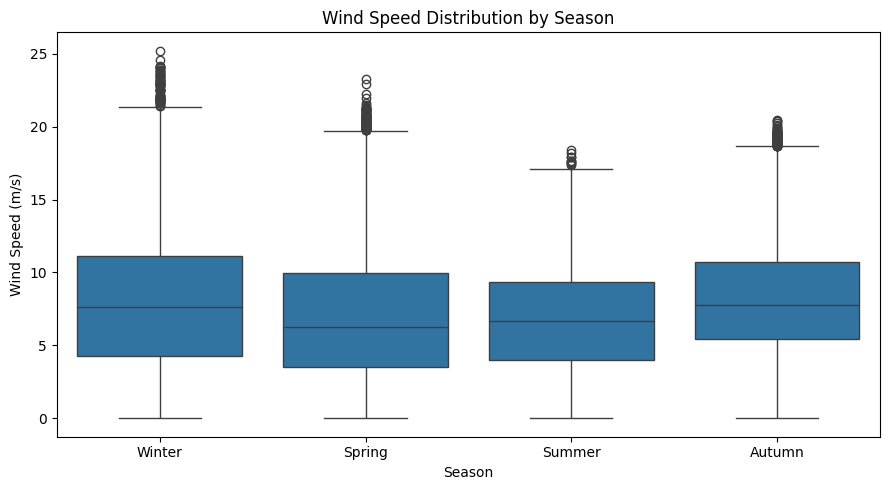

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

season_order = ["Winter", "Spring", "Summer", "Autumn"]

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Season",
    y="Wind Speed (m/s)",
    order=season_order
)

plt.xlabel("Season")
plt.ylabel("Wind Speed (m/s)")
plt.title("Wind Speed Distribution by Season")
plt.tight_layout()
plt.show()

In [76]:
# Check available turbine types
print("Number of turbine types:",
      df["turbine_type"].nunique())

print("\nTurbine types:")
print(df["turbine_type"].value_counts(dropna=False))

Number of turbine types: 1

Turbine types:
turbine_type
S104/3400    50530
Name: count, dtype: int64


In [77]:
import pandas as pd

url = (
    "https://raw.githubusercontent.com/"
    "Divi-patel/wind-power-curves/main/"
    "data/turbine_curves_v1.csv"
)

df_turbines = pd.read_csv(url)

print("Dataset shape:", df_turbines.shape)

print("\nColumns:")
print(df_turbines.columns.tolist())

print("\nNumber of turbine models:",
      df_turbines["turbine_id"].nunique())

display(df_turbines.head())

Dataset shape: (4548, 20)

Columns:
['turbine_id', 'source', 'manufacturer', 'model', 'data_type', 'rated_power_kw', 'rotor_diameter_m', 'hub_height_m', 'air_density_kgm3', 'wind_speed_ms', 'power_kw', 'ct', 'cp', 'turbine_class', 'license', 'source_url', 'access_date', 'notes', 'cut_in_speed_ms', 'cut_out_speed_ms']

Number of turbine models: 93


,turbine_id,source,manufacturer,model,data_type,rated_power_kw,rotor_diameter_m,hub_height_m,air_density_kgm3,wind_speed_ms,power_kw,ct,cp,turbine_class,license,source_url,access_date,notes,cut_in_speed_ms,cut_out_speed_ms
0,2023NREL_Bespoke_8.3MW_196,turbine_models,NaN,2023NREL_Bespoke_8.3MW_196,bespoke,8300.0,196.0,130.0,1.225,0.00,0.0,NaN,0.0,T2,BSD-3-Clause,https://github.com/NREL/turbine-models,2025-10-10,"Group: Onshore, Origin: reference model",3.25,NaN
1,2023NREL_Bespoke_8.3MW_196,turbine_models,NaN,2023NREL_Bespoke_8.3MW_196,bespoke,8300.0,196.0,130.0,1.225,0.25,0.0,NaN,0.0,T2,BSD-3-Clause,https://github.com/NREL/turbine-models,2025-10-10,"Group: Onshore, Origin: reference model",3.25,NaN
2,2023NREL_Bespoke_8.3MW_196,turbine_models,NaN,2023NREL_Bespoke_8.3MW_196,bespoke,8300.0,196.0,130.0,1.225,0.50,0.0,NaN,0.0,T2,BSD-3-Clause,https://github.com/NREL/turbine-models,2025-10-10,"Group: Onshore, Origin: reference model",3.25,NaN
3,2023NREL_Bespoke_8.3MW_196,turbine_models,NaN,2023NREL_Bespoke_8.3MW_196,bespoke,8300.0,196.0,130.0,1.225,0.75,0.0,NaN,0.0,T2,BSD-3-Clause,https://github.com/NREL/turbine-models,2025-10-10,"Group: Onshore, Origin: reference model",3.25,NaN
4,2023NREL_Bespoke_8.3MW_196,turbine_models,NaN,2023NREL_Bespoke_8.3MW_196,bespoke,8300.0,196.0,130.0,1.225,1.00,0.0,NaN,0.0,T2,BSD-3-Clause,https://github.com/NREL/turbine-models,2025-10-10,"Group: Onshore, Origin: reference model",3.25,NaN


In [78]:
# Check missing values
print("Missing values by column:")
display(
    df_turbines.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing_Count")
)

# Check completely empty rows
print(
    "\nCompletely empty rows:",
    df_turbines.isna().all(axis=1).sum()
)

# Check duplicate rows
print(
    "Duplicate rows:",
    df_turbines.duplicated().sum()
)

# Check number of curve points per turbine
curve_points = (
    df_turbines.groupby("turbine_id")
    .agg(
        Curve_Points=("wind_speed_ms", "count"),
        Rated_Power_kW=("rated_power_kw", "first"),
        Rotor_Diameter_m=("rotor_diameter_m", "first")
    )
    .sort_values("Curve_Points")
)

print("\nCurve points per turbine:")
display(curve_points.head(10))
print("\nNumber of turbine models:", len(curve_points))

Missing values by column:


,Missing_Count
ct,4296
turbine_class,4144
cut_out_speed_ms,3331
manufacturer,1869
cp,1003
model,0
turbine_id,0
source,0
hub_height_m,0
data_type,0



Completely empty rows: 0
Duplicate rows: 0

Curve points per turbine:


,Curve_Points,Rated_Power_kW,Rotor_Diameter_m
turbine_id,,,
Vestas_V82,18,1650.0,82.0
S122/3200,20,3200.0,122.0
S122/3000,20,3000.0,122.0
SWT142/3150,21,3150.0,142.0
ENO126/3500,23,3500.0,126.0
ENO114/3500,23,3500.0,114.0
MM100/2000,23,2000.0,100.0
ENO100/2200,23,2200.0,100.0
SWT113/3200,23,3200.0,113.0



Number of turbine models: 93


In [79]:

import pandas as pd
import numpy as np

# 1. Remove completely empty rows, if any
df_turbines = df_turbines.dropna(how="all").copy()

# 2. Check whether power values are physically reasonable
df_turbines["Power_Above_Rated"] = (
    df_turbines["power_kw"] > df_turbines["rated_power_kw"]
)

df_turbines["Negative_Power"] = df_turbines["power_kw"] < 0

# 3. Check duplicate wind-speed points within each turbine curve
duplicate_curve_points = df_turbines.duplicated(
    subset=["turbine_id", "wind_speed_ms"],
    keep=False
)

# 4. Summarize the quality of every turbine model
curve_quality = (
    df_turbines.groupby("turbine_id")
    .agg(
        Curve_Points=("wind_speed_ms", "count"),
        Rated_Power_kW=("rated_power_kw", "first"),
        Min_Wind_Speed=("wind_speed_ms", "min"),
        Max_Wind_Speed=("wind_speed_ms", "max"),
        Min_Power_kW=("power_kw", "min"),
        Max_Power_kW=("power_kw", "max"),
        Points_Above_Rated=("Power_Above_Rated", "sum"),
        Negative_Power_Points=("Negative_Power", "sum")
    )
)

duplicate_counts = (
    df_turbines.assign(Duplicate_Point=duplicate_curve_points)
    .groupby("turbine_id")["Duplicate_Point"]
    .sum()
)

curve_quality["Duplicate_Wind_Speed_Points"] = duplicate_counts

print("Total turbine models:", len(curve_quality))
print(
    "Models with power above rated power:",
    (curve_quality["Points_Above_Rated"] > 0).sum()
)
print(
    "Models with negative power:",
    (curve_quality["Negative_Power_Points"] > 0).sum()
)
print(
    "Models with duplicate wind-speed points:",
    (curve_quality["Duplicate_Wind_Speed_Points"] > 0).sum()
)

print("\nFirst 15 turbine models:")
display(curve_quality.head(15).round(2))


Total turbine models: 93
Models with power above rated power: 26
Models with negative power: 0
Models with duplicate wind-speed points: 0

First 15 turbine models:


,Curve_Points,Rated_Power_kW,Min_Wind_Speed,Max_Wind_Speed,Min_Power_kW,Max_Power_kW,Points_Above_Rated,Negative_Power_Points,Duplicate_Wind_Speed_Points
turbine_id,,,,,,,,,
2017_COE_Market_Average,101,2300.0,0.0,25.0,0.0,2320.0,60,0,0
2018_COE_Market_Average,89,2400.0,3.0,25.0,0.0,2430.0,60,0,0
2019COE_Market_Average_2.6MW_121,161,2550.0,0.0,40.0,0.0,2550.0,0,0,0
2020_ATB_NREL_Reference_4_MW,90,4000.0,3.0,30.0,0.0,4000.0,0,0,0
2020_ATB_NREL_Reference_5.5_MW,89,5500.0,3.0,25.0,0.0,5500.0,0,0,0
2020_ATB_NREL_Reference_7_MW,89,7000.0,3.0,25.0,0.0,7000.0,0,0,0
2023NREL_Bespoke_3.3MW_148,101,3300.0,0.0,25.0,0.0,3303.0,3,0,0
2023NREL_Bespoke_3MW_127.5,101,3000.0,0.0,25.0,0.0,3000.0,0,0,0
2023NREL_Bespoke_6MW_170,101,6000.0,0.0,25.0,0.0,6000.0,0,0,0


In [80]:
# Summarize the size of each model's power excess
power_excess = df_turbines.copy()

power_excess["Excess_kW"] = (
    power_excess["power_kw"] - power_excess["rated_power_kw"]
)

# Keep only points above rated power
power_excess = power_excess[
    power_excess["Excess_kW"] > 0
]

excess_summary = (
    power_excess.groupby("turbine_id")
    .agg(
        Rated_Power_kW=("rated_power_kw", "first"),
        Max_Power_kW=("power_kw", "max"),
        Max_Excess_kW=("Excess_kW", "max"),
        Number_Excess_Points=("Excess_kW", "size")
    )
)

excess_summary["Max_Excess_Percent"] = (
    excess_summary["Max_Excess_kW"]
    / excess_summary["Rated_Power_kW"] * 100
)

excess_summary = excess_summary.sort_values(
    "Max_Excess_Percent",
    ascending=False
)

display(excess_summary.round(2))

,Rated_Power_kW,Max_Power_kW,Max_Excess_kW,Number_Excess_Points,Max_Excess_Percent
turbine_id,,,,,
E-70/2000,2000.0,2050.00,50.00,24,2.50
E-82/2000,2000.0,2050.00,50.00,13,2.50
V112/3000,3000.0,3075.00,75.00,28,2.50
E-82/2300,2300.0,2350.00,50.00,12,2.17
V100/1800/GS,1800.0,1835.00,35.00,20,1.94
V90/2000/GS,2000.0,2030.00,30.00,27,1.50
E-53/800,800.0,810.00,10.00,13,1.25
2018_COE_Market_Average,2400.0,2430.00,30.00,60,1.25
E48/800,800.0,810.00,10.00,12,1.25


In [81]:

# Create one row per turbine model
turbine_catalog = (
    df_turbines.groupby("turbine_id")
    .agg(
        Manufacturer=("manufacturer", "first"),
        Model=("model", "first"),
        Data_Type=("data_type", "first"),
        Rated_Power_kW=("rated_power_kw", "first"),
        Rotor_Diameter_m=("rotor_diameter_m", "first"),
        Hub_Height_m=("hub_height_m", "first"),
        Cut_In_Speed_ms=("cut_in_speed_ms", "first"),
        Cut_Out_Speed_ms=("cut_out_speed_ms", "first"),
        Curve_Points=("wind_speed_ms", "count"),
        Max_Curve_Wind_Speed_ms=("wind_speed_ms", "max")
    )
    .reset_index()
)

# Sort by rated power to understand the range of candidate turbines
turbine_catalog = turbine_catalog.sort_values(
    "Rated_Power_kW"
)

print("Number of candidate turbine models:", len(turbine_catalog))
print("\nRated power range (kW):")
print(
    turbine_catalog["Rated_Power_kW"].min(),
    "to",
    turbine_catalog["Rated_Power_kW"].max()
)

print("\nTurbine catalog:")
display(turbine_catalog)

Number of candidate turbine models: 93

Rated power range (kW):
660.0 to 15000.0

Turbine catalog:


,turbine_id,Manufacturer,Model,Data_Type,Rated_Power_kW,Rotor_Diameter_m,Hub_Height_m,Cut_In_Speed_ms,Cut_Out_Speed_ms,Curve_Points,Max_Curve_Wind_Speed_ms
88,Vestas_V47,None,Vestas_V47,real,660.0,47.00,55.0,4.170000,NaN,29,17.91
27,E-53/800,Enercon,E-53/800,real,800.0,53.00,100.0,3.000000,NaN,25,25.00
35,E48/800,Enercon,E48/800,real,800.0,48.00,100.0,4.000000,NaN,25,25.00
18,DOE_GE_1.5_MW,None,DOE_GE_1.5_MW,real,1500.0,77.00,80.0,3.510000,NaN,42,21.45
89,Vestas_V82,None,Vestas_V82,real,1650.0,82.00,70.0,4.000000,NaN,18,20.00
...,...,...,...,...,...,...,...,...,...,...,...
80,V164/8000,Vestas,V164/8000,real,8000.0,164.00,100.0,3.000000,NaN,26,25.00
10,2023NREL_Bespoke_8.3MW_196,None,2023NREL_Bespoke_8.3MW_196,bespoke,8300.0,196.00,130.0,3.250000,NaN,101,25.00
81,V164/9500,Vestas,V164/9500,real,9500.0,164.00,100.0,3.500000,NaN,49,24.50
90,iea_10MW,IEA,iea_10MW,reference,10000.0,198.00,119.0,4.000000,25.0,24,50.00


In [82]:

# Inspect columns related to wind speed and time
print("Relevant columns:")
print([
    col for col in df.columns
    if any(word in col.lower()
           for word in ["wind", "speed", "timestamp", "date", "time", "density"])
])

print("\nDataframe shape:", df.shape)

# Check whether a timestamp column exists
time_cols = [
    col for col in df.columns
    if any(word in col.lower() for word in ["timestamp", "datetime", "date_time"])
]

print("\nPotential timestamp columns:", time_cols)

# Inspect the available wind-speed columns
wind_cols = [
    col for col in df.columns
    if "wind" in col.lower() or "ws" in col.lower()
]

display(df[wind_cols].describe().T if wind_cols else "No wind columns found")

Relevant columns:
['Date/Time', 'Wind Speed (m/s)', 'Wind Direction (°)', 'Wind_Direction(rad)', 'air_density', 'Wind_Power_Density(W_m2)']

Dataframe shape: (50530, 29)

Potential timestamp columns: []


,count,mean,std,min,25%,50%,75%,max
Wind Speed (m/s),50530.0,7.557952,4.227166,0.000000,4.201395,7.104594,10.300020,25.206011
Wind Direction (°),50530.0,123.687559,93.443736,0.000000,49.315437,73.712978,201.696720,359.997589
Wind_Direction(rad),50530.0,2.158755,1.630901,0.000000,0.860717,1.286534,3.520272,6.283143
ERA5_ws100,50530.0,7.405322,3.964111,0.100000,4.204759,7.102112,10.151355,22.138203
Wind_Power_Density(W_m2),50530.0,525.789031,841.673478,0.000000,41.071694,206.005832,646.942848,9797.883900
ws_lag1,50529.0,7.557904,4.227194,0.000000,4.201378,7.104311,10.300130,25.206011
ws_lag2,50528.0,7.557867,4.227228,0.000000,4.201236,7.104105,10.300220,25.206011
ws_std6,50525.0,0.622462,0.430131,0.025377,0.349982,0.520049,0.771688,8.044054


In [83]:

import pandas as pd

# Convert the timestamp column to datetime
df["Date/Time"] = pd.to_datetime(df["Date/Time"], errors="coerce")

print("Missing or invalid timestamps:", df["Date/Time"].isna().sum())
print("First timestamp:", df["Date/Time"].min())
print("Last timestamp:", df["Date/Time"].max())

# Check duplicated timestamps
print("Duplicate timestamps:", df["Date/Time"].duplicated().sum())

# Check time intervals between consecutive observations
time_diffs = (
    df["Date/Time"]
    .sort_values()
    .diff()
    .dropna()
)

print("\nMost common time intervals:")
display(
    time_diffs.value_counts().head(10).rename_axis("Interval")
    .to_frame("Count")
)

print("\nTime interval summary:")
print(time_diffs.describe())

Missing or invalid timestamps: 0
First timestamp: 2018-01-01 00:00:00
Last timestamp: 2018-12-31 23:50:00
Duplicate timestamps: 0

Most common time intervals:


,Count
Interval,
0 days 00:10:00,50497
0 days 00:20:00,11
0 days 00:40:00,2
0 days 03:00:00,1
4 days 08:20:00,1
0 days 00:50:00,1
0 days 01:40:00,1
0 days 01:00:00,1
0 days 02:10:00,1



Time interval summary:
count                        50529
mean     0 days 00:10:24.104969423
std      0 days 00:43:49.909384776
min                0 days 00:10:00
25%                0 days 00:10:00
50%                0 days 00:10:00
75%                0 days 00:10:00
max                4 days 08:20:00
Name: Date/Time, dtype: object


In [84]:

import pandas as pd
import numpy as np

# Keep the original dataframe unchanged
df_weather = df[
    ["Date/Time", "ERA5_ws100", "air_density"]
].copy()

# Rename columns for easier use
df_weather = df_weather.rename(columns={
    "Date/Time": "Timestamp",
    "ERA5_ws100": "Wind_Speed_100m_ms",
    "air_density": "Air_Density_kgm3"
})

# Remove rows missing essential values
df_weather = df_weather.dropna(
    subset=["Timestamp", "Wind_Speed_100m_ms"]
).copy()

# Remove impossible negative wind speeds
df_weather = df_weather[
    df_weather["Wind_Speed_100m_ms"] >= 0
].copy()

# Sort observations chronologically
df_weather = df_weather.sort_values("Timestamp").reset_index(drop=True)

# Assign Northern Hemisphere meteorological seasons
month_to_season = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

df_weather["Season"] = (
    df_weather["Timestamp"].dt.month.map(month_to_season)
)

# Summarize available observations
season_summary = (
    df_weather.groupby("Season")
    .agg(
        Observations=("Timestamp", "size"),
        First_Timestamp=("Timestamp", "min"),
        Last_Timestamp=("Timestamp", "max"),
        Mean_Wind_Speed_100m=("Wind_Speed_100m_ms", "mean"),
        Max_Wind_Speed_100m=("Wind_Speed_100m_ms", "max")
    )
    .reindex(["Winter", "Spring", "Summer", "Autumn"])
)

display(season_summary.round(2))

,Observations,First_Timestamp,Last_Timestamp,Mean_Wind_Speed_100m,Max_Wind_Speed_100m
Season,,,,,
Winter,12296,2018-01-01,2018-12-31 23:50:00,7.83,22.139999
Spring,13217,2018-03-01,2018-05-31 23:50:00,7.02,20.270000
Summer,13134,2018-06-01,2018-08-31 23:50:00,6.85,16.830000
Autumn,11883,2018-09-01,2018-11-30 23:50:00,8.01,20.010000


In [85]:

# Check weather wind-speed coverage for every candidate turbine

weather_min = df_weather["Wind_Speed_100m_ms"].min()
weather_max = df_weather["Wind_Speed_100m_ms"].max()

coverage_rows = []

for turbine_id, curve in df_turbines.groupby("turbine_id"):
    curve = curve.sort_values("wind_speed_ms")

    curve_min = curve["wind_speed_ms"].min()
    curve_max = curve["wind_speed_ms"].max()

    below = (
        df_weather["Wind_Speed_100m_ms"] < curve_min
    ).sum()

    above = (
        df_weather["Wind_Speed_100m_ms"] > curve_max
    ).sum()

    coverage_rows.append({
        "turbine_id": turbine_id,
        "Curve_Min_Wind_ms": curve_min,
        "Curve_Max_Wind_ms": curve_max,
        "Weather_Min_Wind_ms": weather_min,
        "Weather_Max_Wind_ms": weather_max,
        "Observations_Below_Curve": below,
        "Observations_Above_Curve": above,
        "Rated_Power_kW": curve["rated_power_kw"].iloc[0]
    })

curve_coverage = pd.DataFrame(coverage_rows)

curve_coverage["Percent_Outside_Curve"] = (
    (curve_coverage["Observations_Below_Curve"]
     + curve_coverage["Observations_Above_Curve"])
    / len(df_weather) * 100
)

curve_coverage = curve_coverage.sort_values(
    ["Percent_Outside_Curve", "Rated_Power_kW"]
)

print("Weather wind-speed range:",
      round(weather_min, 2), "to", round(weather_max, 2), "m/s")

print("\nModels with the lowest percentage outside their curve range:")
display(curve_coverage.head(15).round(2))

print("\nModels with the highest percentage outside their curve range:")
display(curve_coverage.tail(10).round(2))

Weather wind-speed range: 0.1 to 22.14 m/s

Models with the lowest percentage outside their curve range:


,turbine_id,Curve_Min_Wind_ms,Curve_Max_Wind_ms,Weather_Min_Wind_ms,Weather_Max_Wind_ms,Observations_Below_Curve,Observations_Above_Curve,Rated_Power_kW,Percent_Outside_Curve
28,E-70/2000,0.0,25.0,0.1,22.14,0,0,2000.0,0.0
82,V80/2000,0.0,25.0,0.1,22.14,0,0,2000.0,0.0
83,V80_HornsRev,0.0,29.5,0.1,22.14,0,0,2000.0,0.0
47,MM92/2050,0.0,25.0,0.1,22.14,0,0,2050.0,0.0
0,2017_COE_Market_Average,0.0,25.0,0.1,22.14,0,0,2300.0,0.0
39,GE100/2500,0.0,35.0,0.1,22.14,0,0,2500.0,0.0
87,VS112/2500,0.0,30.0,0.1,22.14,0,0,2500.0,0.0
2,2019COE_Market_Average_2.6MW_121,0.0,40.0,0.1,22.14,0,0,2550.0,0.0
40,GE103/2750,0.0,25.0,0.1,22.14,0,0,2750.0,0.0
42,GE120/2750,0.0,25.0,0.1,22.14,0,0,2750.0,0.0



Models with the highest percentage outside their curve range:


,turbine_id,Curve_Min_Wind_ms,Curve_Max_Wind_ms,Weather_Min_Wind_ms,Weather_Max_Wind_ms,Observations_Below_Curve,Observations_Above_Curve,Rated_Power_kW,Percent_Outside_Curve
5,2020_ATB_NREL_Reference_7_MW,3.00,25.00,0.1,22.14,7713,0,7000.0,15.26
57,S122/3000,3.00,22.00,0.1,22.14,7713,4,3000.0,15.27
58,S122/3200,3.00,22.00,0.1,22.14,7713,4,3200.0,15.27
89,Vestas_V82,3.00,20.00,0.1,22.14,7713,63,1650.0,15.39
68,V100/1800,3.00,20.00,0.1,22.14,7713,63,1800.0,15.39
69,V100/1800/GS,3.00,20.00,0.1,22.14,7713,63,1800.0,15.39
50,N131/3000,3.00,20.00,0.1,22.14,7713,63,3000.0,15.39
51,N131/3300,3.00,20.00,0.1,22.14,7713,63,3300.0,15.39
85,V90/2000/GS,4.00,25.00,0.1,22.14,11809,0,2000.0,23.37
88,Vestas_V47,4.17,17.91,0.1,22.14,12492,381,660.0,25.48


In [86]:

import numpy as np
import pandas as pd

def estimate_turbine_power(curve, wind_speeds):
    """
    Estimate turbine electrical power (kW) from its power curve.

    Uses linear interpolation within the curve range.
    Does not extrapolate beyond the available curve.
    """
    curve = curve.sort_values("wind_speed_ms")

    ws_curve = curve["wind_speed_ms"].to_numpy(dtype=float)
    power_curve = curve["power_kw"].to_numpy(dtype=float)

    rated_power = float(curve["rated_power_kw"].iloc[0])
    cut_in = curve["cut_in_speed_ms"].iloc[0]
    cut_out = curve["cut_out_speed_ms"].iloc[0]

    wind_speeds = np.asarray(wind_speeds, dtype=float)

    # Interpolate only within the curve range.
    # Outside the curve range, np.interp uses endpoint values,
    # so we explicitly replace those estimates with zero.
    estimated_power = np.interp(
        wind_speeds,
        ws_curve,
        power_curve
    )

    outside_curve = (
        (wind_speeds < ws_curve.min())
        | (wind_speeds > ws_curve.max())
    )
    estimated_power[outside_curve] = np.nan

    # Below cut-in: no generated power
    if pd.notna(cut_in):
        estimated_power[wind_speeds < float(cut_in)] = 0.0

    # Above cut-out: turbine shuts down
    if pd.notna(cut_out):
        estimated_power[wind_speeds >= float(cut_out)] = 0.0

    # Avoid tiny floating-point negatives
    estimated_power = np.maximum(estimated_power, 0.0)

    # Flag rather than silently clipping values above rated power
    return estimated_power


# Test the function on one candidate
test_id = "E-70/2000"
test_curve = df_turbines[
    df_turbines["turbine_id"] == test_id
]

test_wind_speeds = np.array([0, 3, 5, 10, 15, 22])

test_result = pd.DataFrame({
    "Wind_Speed_ms": test_wind_speeds,
    "Estimated_Power_kW": estimate_turbine_power(
        test_curve, test_wind_speeds
    )
})

print("Test turbine:", test_id)
display(test_result)

Test turbine: E-70/2000


,Wind_Speed_ms,Estimated_Power_kW
0,0,0.0
1,3,0.0
2,5,127.0
3,10,1223.0
4,15,2050.0
5,22,2050.0


In [87]:

import numpy as np
import pandas as pd

def estimate_turbine_power(curve, wind_speeds):
    """
    Estimate turbine power in kW.

    Rules:
    - Linear interpolation within the available curve range.
    - Zero power below cut-in speed.
    - Zero power at/above cut-out speed when specified.
    - NaN where the curve does not support an estimate.
    - Cap output at rated power and document the adjustment.
    """
    curve = curve.sort_values("wind_speed_ms")

    ws_curve = curve["wind_speed_ms"].to_numpy(dtype=float)
    power_curve = curve["power_kw"].to_numpy(dtype=float)

    rated_power = float(curve["rated_power_kw"].iloc[0])
    cut_in = curve["cut_in_speed_ms"].iloc[0]
    cut_out = curve["cut_out_speed_ms"].iloc[0]

    ws = np.asarray(wind_speeds, dtype=float)

    power = np.interp(ws, ws_curve, power_curve)

    # Do not extrapolate beyond the available curve.
    outside_curve = (ws < ws_curve.min()) | (ws > ws_curve.max())
    power[outside_curve] = np.nan

    # Apply documented operational limits where available.
    if pd.notna(cut_in):
        power[ws < float(cut_in)] = 0.0

    if pd.notna(cut_out):
        power[ws >= float(cut_out)] = 0.0

    # Prevent estimated output from exceeding stated rated power.
    # The source curve itself remains unchanged.
    valid = np.isfinite(power)
    power[valid] = np.clip(power[valid], 0.0, rated_power)

    return power


# Retest
test_id = "E-70/2000"
test_curve = df_turbines[
    df_turbines["turbine_id"] == test_id
]

test_wind_speeds = np.array([0, 3, 5, 10, 15, 22, 26])

display(pd.DataFrame({
    "Wind_Speed_ms": test_wind_speeds,
    "Estimated_Power_kW": estimate_turbine_power(
        test_curve, test_wind_speeds
    )
}))

,Wind_Speed_ms,Estimated_Power_kW
0,0,0.0
1,3,0.0
2,5,127.0
3,10,1223.0
4,15,2000.0
5,22,2000.0
6,26,NaN


In [88]:

import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Prepare observation durations
# --------------------------------------------------
weather = df_weather.sort_values("Timestamp").copy()
weather = weather.reset_index(drop=True)

next_timestamp = weather["Timestamp"].shift(-1)

duration = next_timestamp - weather["Timestamp"]
duration = duration.fillna(pd.Timedelta(minutes=10))

# Never extend an observation across a gap longer than 10 minutes.
duration = duration.clip(upper=pd.Timedelta(minutes=10))

weather["Duration_hours"] = duration.dt.total_seconds() / 3600

# --------------------------------------------------
# 2. Estimate power for every candidate turbine
# --------------------------------------------------
wind_speeds = weather["Wind_Speed_100m_ms"].to_numpy()
duration_hours = weather["Duration_hours"].to_numpy()
seasons = weather["Season"].to_numpy()

results = []

turbine_groups = list(df_turbines.groupby("turbine_id"))
total_models = len(turbine_groups)

for i, (turbine_id, curve) in enumerate(turbine_groups, start=1):

    power_kw = estimate_turbine_power(curve, wind_speeds)

    rated_power = float(curve["rated_power_kw"].iloc[0])

    # An estimate is supported when it is finite.
    supported = np.isfinite(power_kw)

    for season in ["Winter", "Spring", "Summer", "Autumn"]:

        mask = seasons == season

        season_power = power_kw[mask]
        season_duration = duration_hours[mask]
        season_supported = supported[mask]

        total_hours = season_duration.sum()
        supported_hours = season_duration[season_supported].sum()

        # Sum energy only where the curve supports an estimate.
        energy_mwh = (
            np.sum(
                season_power[season_supported]
                * season_duration[season_supported]
            ) / 1000
        )

        mean_power_kw = (
            np.average(
                season_power[season_supported],
                weights=season_duration[season_supported]
            )
            if season_supported.any()
            else np.nan
        )

        results.append({
            "turbine_id": turbine_id,
            "Season": season,
            "Rated_Power_kW": rated_power,
            "Estimated_Energy_MWh": energy_mwh,
            "Mean_Estimated_Power_kW": mean_power_kw,
            "Coverage_Percent": (
                supported_hours / total_hours * 100
                if total_hours > 0 else np.nan
            )
        })

    if i % 10 == 0 or i == total_models:
        print(f"Processed {i}/{total_models} turbine models")

seasonal_results = pd.DataFrame(results)

# --------------------------------------------------
# 3. Show the highest-energy models for each season
# --------------------------------------------------
for season in ["Winter", "Spring", "Summer", "Autumn"]:

    print(f"\nTop 10 turbine models by estimated energy — {season}")

    top_models = (
        seasonal_results[
            seasonal_results["Season"] == season
        ]
        .sort_values("Estimated_Energy_MWh", ascending=False)
        .head(10)
    )

    display(
        top_models[
            [
                "turbine_id",
                "Rated_Power_kW",
                "Estimated_Energy_MWh",
                "Mean_Estimated_Power_kW",
                "Coverage_Percent"
            ]
        ].round(2)
    )


Processed 10/93 turbine models
Processed 20/93 turbine models
Processed 30/93 turbine models
Processed 40/93 turbine models
Processed 50/93 turbine models
Processed 60/93 turbine models
Processed 70/93 turbine models
Processed 80/93 turbine models
Processed 90/93 turbine models
Processed 93/93 turbine models

Top 10 turbine models by estimated energy — Winter


,turbine_id,Rated_Power_kW,Estimated_Energy_MWh,Mean_Estimated_Power_kW,Coverage_Percent
364,iea_15MW,15000.0,14221.91,6939.77,100.0
360,iea_10MW,10000.0,9652.34,4709.99,100.0
40,2023NREL_Bespoke_8.3MW_196,8300.0,8556.16,4175.10,100.0
320,V164/8000,8000.0,8499.53,4147.46,100.0
68,BAR_LowSP_6.5MW,6500.0,7894.26,3852.11,100.0
324,V164/9500,9500.0,7661.51,3738.54,100.0
20,2020_ATB_NREL_Reference_7_MW,7000.0,7469.84,3645.01,100.0
36,2023NREL_Bespoke_6MW_196,6000.0,6967.07,3399.68,100.0
240,S152/6330,6330.0,6692.88,3265.88,100.0
244,SCD168/8000,8000.0,6619.42,3230.04,100.0



Top 10 turbine models by estimated energy — Spring


,turbine_id,Rated_Power_kW,Estimated_Energy_MWh,Mean_Estimated_Power_kW,Coverage_Percent
365,iea_15MW,15000.0,12448.89,5651.31,100.0
361,iea_10MW,10000.0,8450.62,3836.25,100.0
41,2023NREL_Bespoke_8.3MW_196,8300.0,7533.93,3420.11,100.0
321,V164/8000,8000.0,7503.98,3406.51,100.0
69,BAR_LowSP_6.5MW,6500.0,6996.79,3176.27,100.0
325,V164/9500,9500.0,6716.39,3048.98,100.0
21,2020_ATB_NREL_Reference_7_MW,7000.0,6543.01,2970.27,100.0
37,2023NREL_Bespoke_6MW_196,6000.0,6181.69,2806.24,100.0
241,S152/6330,6330.0,5901.06,2678.85,100.0
245,SCD168/8000,8000.0,5785.96,2626.60,100.0



Top 10 turbine models by estimated energy — Summer


,turbine_id,Rated_Power_kW,Estimated_Energy_MWh,Mean_Estimated_Power_kW,Coverage_Percent
366,iea_15MW,15000.0,12342.41,5638.38,100.0
362,iea_10MW,10000.0,8418.09,3845.63,100.0
322,V164/8000,8000.0,7621.09,3481.54,100.0
42,2023NREL_Bespoke_8.3MW_196,8300.0,7606.45,3474.85,100.0
70,BAR_LowSP_6.5MW,6500.0,7330.90,3348.97,100.0
22,2020_ATB_NREL_Reference_7_MW,7000.0,6645.10,3035.68,100.0
38,2023NREL_Bespoke_6MW_196,6000.0,6404.70,2925.85,100.0
326,V164/9500,9500.0,6396.20,2921.97,100.0
242,S152/6330,6330.0,6024.90,2752.35,100.0
34,2023NREL_Bespoke_6MW_170,6000.0,5612.27,2563.85,100.0



Top 10 turbine models by estimated energy — Autumn


,turbine_id,Rated_Power_kW,Estimated_Energy_MWh,Mean_Estimated_Power_kW,Coverage_Percent
367,iea_15MW,15000.0,14292.73,7216.73,100.0
363,iea_10MW,10000.0,9722.34,4909.03,100.0
43,2023NREL_Bespoke_8.3MW_196,8300.0,8645.07,4365.09,100.0
323,V164/8000,8000.0,8609.18,4346.97,100.0
71,BAR_LowSP_6.5MW,6500.0,8117.81,4098.87,100.0
327,V164/9500,9500.0,7553.16,3813.77,100.0
23,2020_ATB_NREL_Reference_7_MW,7000.0,7552.17,3813.26,100.0
39,2023NREL_Bespoke_6MW_196,6000.0,7126.46,3598.31,100.0
243,S152/6330,6330.0,6791.90,3429.39,100.0
247,SCD168/8000,8000.0,6548.49,3306.48,100.0


In [89]:
import numpy as np
import pandas as pd

weather_ws = df_weather["Wind_Speed_100m_ms"].dropna()

weather_min = weather_ws.min()
weather_max = weather_ws.max()

diagnostics = []

for turbine_id, curve in df_turbines.groupby("turbine_id"):

    curve = curve.sort_values("wind_speed_ms")

    curve_min = curve["wind_speed_ms"].min()
    curve_max = curve["wind_speed_ms"].max()

    rated_power = curve["rated_power_kw"].iloc[0]
    hub_height = curve["hub_height_m"].iloc[0]
    cut_in = curve["cut_in_speed_ms"].iloc[0]
    cut_out = curve["cut_out_speed_ms"].iloc[0]

    diagnostics.append({
        "turbine_id": turbine_id,
        "Rated_Power_kW": rated_power,
        "Hub_Height_m": hub_height,
        "Curve_Min_Wind_ms": curve_min,
        "Curve_Max_Wind_ms": curve_max,
        "Weather_Min_Wind_ms": weather_min,
        "Weather_Max_Wind_ms": weather_max,
        "Curve_Covers_Weather_Range": (
            curve_min <= weather_min and curve_max >= weather_max
        ),
        "Cut_In_Available": pd.notna(cut_in),
        "Cut_Out_Available": pd.notna(cut_out)
    })

curve_diagnostics = pd.DataFrame(diagnostics)

print("Weather wind-speed range:",
      round(weather_min, 2), "to", round(weather_max, 2), "m/s")

print(
    "Models whose curves cover the full observed range:",
    curve_diagnostics["Curve_Covers_Weather_Range"].sum(),
    "out of", len(curve_diagnostics)
)

display(
    curve_diagnostics.sort_values(
        ["Curve_Covers_Weather_Range", "Rated_Power_kW"],
        ascending=[False, False]
    ).head(20)
)

Weather wind-speed range: 0.1 to 22.14 m/s
Models whose curves cover the full observed range: 39 out of 93


,turbine_id,Rated_Power_kW,Hub_Height_m,Curve_Min_Wind_ms,Curve_Max_Wind_ms,Weather_Min_Wind_ms,Weather_Max_Wind_ms,Curve_Covers_Weather_Range,Cut_In_Available,Cut_Out_Available
91,iea_15MW,15000.0,150.0,0.0,50.0,0.1,22.138203,True,True,True
90,iea_10MW,10000.0,119.0,0.0,50.0,0.1,22.138203,True,True,True
81,V164/9500,9500.0,100.0,0.0,24.5,0.1,22.138203,True,True,False
10,2023NREL_Bespoke_8.3MW_196,8300.0,130.0,0.0,25.0,0.1,22.138203,True,True,False
80,V164/8000,8000.0,100.0,0.0,25.0,0.1,22.138203,True,True,False
25,E-126/7580,7580.0,100.0,0.0,35.0,0.1,22.138203,True,True,True
24,E-126/7500,7500.0,100.0,0.0,25.0,0.1,22.138203,True,True,False
17,BAR_LowSP_6.5MW,6500.0,150.0,0.0,25.0,0.1,22.138203,True,True,False
60,S152/6330,6330.0,100.0,0.0,32.0,0.1,22.138203,True,True,False
59,S126/6150,6150.0,100.0,0.0,30.0,0.1,22.138203,True,True,False


In [91]:

import pandas as pd
import numpy as np

# Wind-speed range from the main weather data
weather_min = df_weather["Wind_Speed_100m_ms"].min()
weather_max = df_weather["Wind_Speed_100m_ms"].max()

coverage_rows = []

for turbine_id, curve in df_turbines.groupby("turbine_id"):

    ws_min = curve["wind_speed_ms"].min()
    ws_max = curve["wind_speed_ms"].max()

    coverage_rows.append({
        "turbine_id": turbine_id,
        "Rated_Power_kW": curve["rated_power_kw"].iloc[0],
        "Hub_Height_m": curve["hub_height_m"].iloc[0],
        "Curve_Min_Wind_ms": ws_min,
        "Curve_Max_Wind_ms": ws_max,
        "Weather_Min_Wind_ms": weather_min,
        "Weather_Max_Wind_ms": weather_max,
        "Curve_Covers_Weather_Range": (
            ws_min <= weather_min and ws_max >= weather_max
        ),
        "Cut_In_Available": curve["cut_in_speed_ms"].notna().any(),
        "Cut_Out_Available": curve["cut_out_speed_ms"].notna().any()
    })

coverage_df = pd.DataFrame(coverage_rows)

print("Models covering the full observed wind-speed range:",
      coverage_df["Curve_Covers_Weather_Range"].sum(),
      "out of", len(coverage_df))

display(
    coverage_df[
        coverage_df["Curve_Covers_Weather_Range"]
    ].sort_values("Rated_Power_kW", ascending=False).head(10)
)

Models covering the full observed wind-speed range: 39 out of 93


,turbine_id,Rated_Power_kW,Hub_Height_m,Curve_Min_Wind_ms,Curve_Max_Wind_ms,Weather_Min_Wind_ms,Weather_Max_Wind_ms,Curve_Covers_Weather_Range,Cut_In_Available,Cut_Out_Available
91,iea_15MW,15000.0,150.0,0.0,50.0,0.1,22.138203,True,True,True
90,iea_10MW,10000.0,119.0,0.0,50.0,0.1,22.138203,True,True,True
81,V164/9500,9500.0,100.0,0.0,24.5,0.1,22.138203,True,True,False
10,2023NREL_Bespoke_8.3MW_196,8300.0,130.0,0.0,25.0,0.1,22.138203,True,True,False
80,V164/8000,8000.0,100.0,0.0,25.0,0.1,22.138203,True,True,False
25,E-126/7580,7580.0,100.0,0.0,35.0,0.1,22.138203,True,True,True
24,E-126/7500,7500.0,100.0,0.0,25.0,0.1,22.138203,True,True,False
17,BAR_LowSP_6.5MW,6500.0,150.0,0.0,25.0,0.1,22.138203,True,True,False
60,S152/6330,6330.0,100.0,0.0,32.0,0.1,22.138203,True,True,False
59,S126/6150,6150.0,100.0,0.0,30.0,0.1,22.138203,True,True,False


In [93]:
suitable_turbine_ids = coverage_df.loc[
    coverage_df["Curve_Covers_Weather_Range"],
    "turbine_id"
].unique()

df_turbines_suitable = df_turbines[
    df_turbines["turbine_id"].isin(suitable_turbine_ids)
].copy()

print("Suitable turbine models:",
      df_turbines_suitable["turbine_id"].nunique())

print("Main weather dataframe shape:", df.shape)

Suitable turbine models: 39
Main weather dataframe shape: (50530, 29)


In [94]:

# Use the main dataframe's weather observations
weather = df_weather.copy()

wind_speeds = weather["Wind_Speed_100m_ms"].to_numpy()

# Estimate output for each of the 39 suitable turbines
power_results = weather[["Timestamp", "Season"]].copy()

for i, (turbine_id, curve) in enumerate(
    df_turbines_suitable.groupby("turbine_id"),
    start=1
):
    power_results[turbine_id] = estimate_turbine_power(
        curve,
        wind_speeds
    )

    if i % 10 == 0 or i == df_turbines_suitable["turbine_id"].nunique():
        print(f"Processed {i}/{df_turbines_suitable['turbine_id'].nunique()} turbines")

display(power_results.head())
print("Power-results shape:", power_results.shape)

Processed 10/39 turbines
Processed 20/39 turbines
Processed 30/39 turbines
Processed 39/39 turbines


,Timestamp,Season,2017_COE_Market_Average,2019COE_Market_Average_2.6MW_121,2023NREL_Bespoke_3.3MW_148,2023NREL_Bespoke_3MW_127.5,2023NREL_Bespoke_6MW_170,2023NREL_Bespoke_6MW_196,2023NREL_Bespoke_8.3MW_196,AD116/5000,...,V126/3300,V126/3450,V164/8000,V164/9500,V80/2000,V80_HornsRev,VS112/2500,iea_10MW,iea_15MW,nrel_5MW
0,2018-01-01 00:00:00,Winter,332.487627,384.243515,727.493050,540.028236,959.219437,1275.306539,1274.892352,348.400459,...,471.714348,480.818977,1365.342857,764.007168,196.569443,187.674072,377.092103,1232.238975,1682.396004,491.687103
1,2018-01-01 00:10:00,Winter,428.244180,494.321487,911.792023,676.222122,1202.312241,1599.379822,1598.670276,458.346329,...,602.965912,615.081596,1754.720383,1021.237717,247.313690,241.801270,475.451369,1589.612273,2186.128049,632.793356
2,2018-01-01 00:20:00,Winter,327.525599,378.554586,717.752703,532.868155,946.422741,1258.260643,1257.881030,342.211370,...,464.953959,473.868155,1343.423961,750.343564,193.712940,184.627136,371.555249,1212.121666,1656.387771,483.743929
3,2018-01-01 00:30:00,Winter,428.244180,494.321487,911.792023,676.222122,1202.312241,1599.379822,1598.670276,458.346329,...,602.965912,615.081596,1754.720383,1021.237717,247.313690,241.801270,475.451369,1589.612273,2186.128049,632.793356
4,2018-01-01 00:40:00,Winter,391.534016,451.756475,841.467220,623.786963,1109.162722,1475.382702,1474.654335,418.248854,...,549.913868,561.104226,1612.713633,920.685587,228.807163,222.060974,439.579551,1459.277527,1993.032103,581.331628


Power-results shape: (50530, 41)


In [95]:

columns_to_check = [
    "Timestamp",
    "Season",
    "S104/3400",
    "iea_10MW",
    "iea_15MW"
]

display(power_results[columns_to_check].head(10))


,Timestamp,Season,S104/3400,iea_10MW,iea_15MW
0,2018-01-01 00:00:00,Winter,304.910205,1232.238975,1682.396004
1,2018-01-01 00:10:00,Winter,399.475286,1589.612273,2186.128049
2,2018-01-01 00:20:00,Winter,300.068434,1212.121666,1656.387771
3,2018-01-01 00:30:00,Winter,399.475286,1589.612273,2186.128049
4,2018-01-01 00:40:00,Winter,361.012554,1459.277527,1993.032103
5,2018-01-01 00:50:00,Winter,361.012554,1459.277527,1993.032103
6,2018-01-01 01:00:00,Winter,416.913112,1648.702059,2273.671844
7,2018-01-01 01:10:00,Winter,308.382788,1246.667375,1701.049451
8,2018-01-01 01:20:00,Winter,340.454713,1379.924552,1875.467613
9,2018-01-01 01:30:00,Winter,340.454713,1379.924552,1875.467613


In [96]:

import numpy as np
import pandas as pd

weather = df_weather.sort_values("Timestamp").reset_index(drop=True).copy()

# Duration represented by each observation, capped at 10 minutes
next_timestamp = weather["Timestamp"].shift(-1)
duration = (next_timestamp - weather["Timestamp"]).fillna(
    pd.Timedelta(minutes=10)
)
duration = duration.clip(upper=pd.Timedelta(minutes=10))

weather["Duration_hours"] = duration.dt.total_seconds() / 3600

duration_hours = weather["Duration_hours"].to_numpy()

seasonal_rows = []

turbine_columns = [
    col for col in power_results.columns
    if col not in ["Timestamp", "Season"]
]

for turbine_id in turbine_columns:
    for season in ["Winter", "Spring", "Summer", "Autumn"]:

        mask = power_results["Season"].eq(season).to_numpy()

        power = power_results.loc[mask, turbine_id].to_numpy(dtype=float)
        hours = duration_hours[mask]

        valid = np.isfinite(power)

        total_hours = hours.sum()
        supported_hours = hours[valid].sum()

        energy_mwh = (power[valid] * hours[valid]).sum() / 1000

        seasonal_rows.append({
            "turbine_id": turbine_id,
            "Season": season,
            "Estimated_Energy_MWh": energy_mwh,
            "Coverage_Percent": (
                100 * supported_hours / total_hours
                if total_hours > 0 else np.nan
            )
        })

seasonal_39_results = pd.DataFrame(seasonal_rows)

# Show the top 10 models for each season
for season in ["Winter", "Spring", "Summer", "Autumn"]:

    print(f"\nTop 10 turbines — {season}")

    top10 = (
        seasonal_39_results[
            seasonal_39_results["Season"].eq(season)
        ]
        .sort_values("Estimated_Energy_MWh", ascending=False)
        .head(10)
    )

    display(top10.round(2))


Top 10 turbines — Winter


,turbine_id,Season,Estimated_Energy_MWh,Coverage_Percent
148,iea_15MW,Winter,14221.91,100.0
144,iea_10MW,Winter,9652.34,100.0
24,2023NREL_Bespoke_8.3MW_196,Winter,8556.16,100.0
124,V164/8000,Winter,8499.53,100.0
52,BAR_LowSP_6.5MW,Winter,7894.26,100.0
128,V164/9500,Winter,7661.51,100.0
20,2023NREL_Bespoke_6MW_196,Winter,6967.07,100.0
100,S152/6330,Winter,6692.88,100.0
16,2023NREL_Bespoke_6MW_170,Winter,6287.62,100.0
48,BAR_LowSP_4.5MW,Winter,5453.70,100.0



Top 10 turbines — Spring


,turbine_id,Season,Estimated_Energy_MWh,Coverage_Percent
149,iea_15MW,Spring,12448.89,100.0
145,iea_10MW,Spring,8450.62,100.0
25,2023NREL_Bespoke_8.3MW_196,Spring,7533.93,100.0
125,V164/8000,Spring,7503.98,100.0
53,BAR_LowSP_6.5MW,Spring,6996.79,100.0
129,V164/9500,Spring,6716.39,100.0
21,2023NREL_Bespoke_6MW_196,Spring,6181.69,100.0
101,S152/6330,Spring,5901.06,100.0
17,2023NREL_Bespoke_6MW_170,Spring,5538.87,100.0
49,BAR_LowSP_4.5MW,Spring,4832.14,100.0



Top 10 turbines — Summer


,turbine_id,Season,Estimated_Energy_MWh,Coverage_Percent
150,iea_15MW,Summer,12342.41,100.0
146,iea_10MW,Summer,8418.09,100.0
126,V164/8000,Summer,7621.09,100.0
26,2023NREL_Bespoke_8.3MW_196,Summer,7606.45,100.0
54,BAR_LowSP_6.5MW,Summer,7330.90,100.0
22,2023NREL_Bespoke_6MW_196,Summer,6404.70,100.0
130,V164/9500,Summer,6396.20,100.0
102,S152/6330,Summer,6024.90,100.0
18,2023NREL_Bespoke_6MW_170,Summer,5612.27,100.0
50,BAR_LowSP_4.5MW,Summer,5060.42,100.0



Top 10 turbines — Autumn


,turbine_id,Season,Estimated_Energy_MWh,Coverage_Percent
151,iea_15MW,Autumn,14292.73,100.0
147,iea_10MW,Autumn,9722.34,100.0
27,2023NREL_Bespoke_8.3MW_196,Autumn,8645.07,100.0
127,V164/8000,Autumn,8609.18,100.0
55,BAR_LowSP_6.5MW,Autumn,8117.81,100.0
131,V164/9500,Autumn,7553.16,100.0
23,2023NREL_Bespoke_6MW_196,Autumn,7126.46,100.0
103,S152/6330,Autumn,6791.90,100.0
19,2023NREL_Bespoke_6MW_170,Autumn,6361.83,100.0
51,BAR_LowSP_4.5MW,Autumn,5606.17,100.0


In [97]:

# Keep only the 39 turbine power columns
turbine_columns = [
    col for col in power_results.columns
    if col not in ["Timestamp", "Season"]
]

# Prepare the power estimates for merging
power_to_add = power_results[
    ["Timestamp"] + turbine_columns
].copy()

# Ensure timestamps use the same format
df["Date/Time"] = pd.to_datetime(df["Date/Time"])
power_to_add["Timestamp"] = pd.to_datetime(power_to_add["Timestamp"])

# Merge estimates into the original dataframe
df = df.merge(
    power_to_add,
    left_on="Date/Time",
    right_on="Timestamp",
    how="left",
    validate="one_to_one"
)

# Remove the extra timestamp column created by the merge
df = df.drop(columns=["Timestamp"])

print("Updated main dataframe shape:", df.shape)
print("Number of turbine power columns added:", len(turbine_columns))

display(df.head())

Updated main dataframe shape: (50530, 68)
Number of turbine power columns added: 39


,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°),LVActive_Power(W),Theoretical_Power(W),Wind_Direction(rad),Month,Latitude,...,V126/3300,V126/3450,V164/8000,V164/9500,V80/2000,V80_HornsRev,VS112/2500,iea_10MW,iea_15MW,nrel_5MW
0,2018-01-01 00:00:00,380.047791,5.311336,416.328908,259.994904,380047.790527,416328.907825,4.537767,1,41.5,...,471.714348,480.818977,1365.342857,764.007168,196.569443,187.674072,377.092103,1232.238975,1682.396004,491.687103
1,2018-01-01 00:10:00,453.769196,5.672167,519.917511,268.641113,453769.195557,519917.511061,4.688672,1,42.5,...,602.965912,615.081596,1754.720383,1021.237717,247.313690,241.801270,475.451369,1589.612273,2186.128049,632.793356
2,2018-01-01 00:20:00,306.376587,5.216037,390.900016,272.564789,306376.586914,390900.015811,4.757153,1,42.5,...,464.953959,473.868155,1343.423961,750.343564,193.712940,184.627136,371.555249,1212.121666,1656.387771,483.743929
3,2018-01-01 00:30:00,419.645905,5.659674,516.127569,271.258087,419645.904541,516127.568976,4.734347,1,42.5,...,602.965912,615.081596,1754.720383,1021.237717,247.313690,241.801270,475.451369,1589.612273,2186.128049,632.793356
4,2018-01-01 00:40:00,380.650696,5.577941,491.702972,265.674286,380650.695801,491702.971954,4.636891,1,35.5,...,549.913868,561.104226,1612.713633,920.685587,228.807163,222.060974,439.579551,1459.277527,1993.032103,581.331628


In [99]:

# The best candidate from our seasonal energy comparison
best_turbine = "iea_15MW"

# Remove the other 38 candidate turbine columns from df
other_turbine_columns = [
    col for col in turbine_columns
    if col != best_turbine
]

df = df.drop(
    columns=[
        col for col in other_turbine_columns
        if col in df.columns
    ]
)

print("Best turbine:", best_turbine)
print("Main dataframe shape:", df.shape)
print("Best turbine column exists:", best_turbine in df.columns)

display(
    df[
        [
            "Date/Time",
            "Wind Speed (m/s)",
            "ERA5_ws100",
            best_turbine,
            "LV ActivePower (kW)"
        ]
    ].head(10)
)

Best turbine: iea_15MW
Main dataframe shape: (50530, 30)
Best turbine column exists: True


,Date/Time,Wind Speed (m/s),ERA5_ws100,iea_15MW,LV ActivePower (kW)
0,2018-01-01 00:00:00,5.311336,5.263079,1682.396004,380.047791
1,2018-01-01 00:10:00,5.672167,5.685947,2186.128049,453.769196
2,2018-01-01 00:20:00,5.216037,5.239275,1656.387771,306.376587
3,2018-01-01 00:30:00,5.659674,5.685947,2186.128049,419.645905
4,2018-01-01 00:40:00,5.577941,5.531726,1993.032103,380.650696
5,2018-01-01 00:50:00,5.604052,5.531726,1993.032103,402.391998
6,2018-01-01 01:00:00,5.793008,5.755867,2273.671844,447.605713
7,2018-01-01 01:10:00,5.306050,5.280151,1701.049451,387.242188
8,2018-01-01 01:20:00,5.584629,5.437830,1875.467613,463.651215
9,2018-01-01 01:30:00,5.523228,5.437830,1875.467613,439.725708


In [100]:
df.head()

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°),LVActive_Power(W),Theoretical_Power(W),Wind_Direction(rad),Month,Latitude,...,best_turbine_err(W),curve_S104(W),dir_sin,dir_cos,ws_lag1,ws_lag2,ws_std6,pow_lag1,Season,iea_15MW
0,2018-01-01 00:00:00,380.047791,5.311336,416.328908,259.994904,380047.790527,416328.907825,4.537767,1,41.5,...,3491.799501,317075.592199,-0.984792,-0.173736,NaN,NaN,NaN,NaN,Winter,1682.396004
1,2018-01-01 00:10:00,453.769196,5.672167,519.917511,268.641113,453769.195557,519917.511061,4.688672,1,42.5,...,20936.536273,415167.728917,-0.999719,-0.023715,5.311336,NaN,NaN,380047.790527,Winter,2186.128049
2,2018-01-01 00:20:00,306.376587,5.216037,390.900016,272.564789,306376.586914,390900.015811,4.757153,1,42.5,...,392.157313,303031.812879,-0.998998,0.044749,5.672167,5.311336,NaN,453769.195557,Winter,1656.387771
3,2018-01-01 00:30:00,419.645905,5.659674,516.127569,271.258087,419645.904541,516127.568976,4.734347,1,42.5,...,7625.276394,412009.928980,-0.999759,0.021956,5.216037,5.672167,NaN,306376.586914,Winter,2186.128049
4,2018-01-01 00:40:00,380.650696,5.577941,491.702972,265.674286,380650.695801,491702.971954,4.636891,1,35.5,...,13931.335468,357055.214123,-0.997151,-0.075426,5.659674,5.216037,NaN,419645.904541,Winter,1993.032103


In [102]:
best_turbine_id = "iea_15MW"

# Get the turbine's details from the catalog
best_turbine_info = df_turbines[
    df_turbines["turbine_id"] == best_turbine_id
].iloc[0]

# Add a readable turbine name to every row
df["Best_Turbine_Name"] = (
    best_turbine_info["manufacturer"]
    if pd.notna(best_turbine_info["manufacturer"])
    else "Unknown manufacturer"
)

df["Best_Turbine_Model"] = best_turbine_info["model"]
df["Best_Turbine_Rated_Power_kW"] = best_turbine_info["rated_power_kw"]

# Display the result clearly
display(
    df[
        [
            "Date/Time",
            "Wind Speed (m/s)",
            "Best_Turbine_Name",
            "Best_Turbine_Model",
            "Best_Turbine_Rated_Power_kW",
            "iea_15MW"
        ]
    ].head(10)
)

display(
    df_turbines.loc[
        df_turbines["turbine_id"] == "iea_15MW",
        ["turbine_id", "manufacturer", "model", "rated_power_kw"]
    ].drop_duplicates()
)

,Date/Time,Wind Speed (m/s),Best_Turbine_Name,Best_Turbine_Model,Best_Turbine_Rated_Power_kW,iea_15MW
0,2018-01-01 00:00:00,5.311336,IEA,iea_15MW,15000.0,1682.396004
1,2018-01-01 00:10:00,5.672167,IEA,iea_15MW,15000.0,2186.128049
2,2018-01-01 00:20:00,5.216037,IEA,iea_15MW,15000.0,1656.387771
3,2018-01-01 00:30:00,5.659674,IEA,iea_15MW,15000.0,2186.128049
4,2018-01-01 00:40:00,5.577941,IEA,iea_15MW,15000.0,1993.032103
5,2018-01-01 00:50:00,5.604052,IEA,iea_15MW,15000.0,1993.032103
6,2018-01-01 01:00:00,5.793008,IEA,iea_15MW,15000.0,2273.671844
7,2018-01-01 01:10:00,5.306050,IEA,iea_15MW,15000.0,1701.049451
8,2018-01-01 01:20:00,5.584629,IEA,iea_15MW,15000.0,1875.467613
9,2018-01-01 01:30:00,5.523228,IEA,iea_15MW,15000.0,1875.467613


,turbine_id,manufacturer,model,rated_power_kw
4296,iea_15MW,IEA,iea_15MW,15000.0


In [52]:
"""
2. Get your Feedin Time Series

The DataFrame needs to have pressure, wind speed, temperature and the roughness length. 
The following names are used:
        ‘pressure’
        ‘temp_air’
        ‘v_wind’
        ‘z0’

'pressure': 'pressure',
'ambient temperature': 'temp_air',
'wind speed': 'v_wind',
'roughness length': 'z0'
"""

"\n2. Get your Feedin Time Series\n\nThe DataFrame needs to have pressure, wind speed, temperature and the roughness length. \nThe following names are used:\n        ‘pressure’\n        ‘temp_air’\n        ‘v_wind’\n        ‘z0’\n\n'pressure': 'pressure',\n'ambient temperature': 'temp_air',\n'wind speed': 'v_wind',\n'roughness length': 'z0'\n"

In [103]:

# Check available weather-related columns
weather_columns = [
    col for col in df.columns
    if any(term in col.lower() for term in [
        "pressure", "temp", "wind", "rough", "z0", "density"
    ])
]

print("Weather-related columns:")
print(weather_columns)

display(df[weather_columns].head())


Weather-related columns:
['Wind Speed (m/s)', 'Wind Direction (°)', 'Wind_Direction(rad)', 'Temperature', 'Pressure', 'air_density', 'Wind_Power_Density(W_m2)']


,Wind Speed (m/s),Wind Direction (°),Wind_Direction(rad),Temperature,Pressure,air_density,Wind_Power_Density(W_m2)
0,5.311336,259.994904,4.537767,284.750000,101500.000000,1.233011,92.373691
1,5.672167,268.641113,4.688672,276.372986,101890.000000,1.275370,116.373246
2,5.216037,272.564789,4.757153,281.449982,101850.000000,1.251831,88.825475
3,5.659674,271.258087,4.734347,276.372986,101890.000000,1.275370,115.606020
4,5.577941,265.674286,4.636891,285.299988,97732.234375,1.184551,102.788741


In [104]:
weather_check_cols = [
    col for col in df.columns
    if col in [
        "Temperature",
        "Pressure",
        "Wind Speed (m/s)",
        "ERA5_ws100",
        "air_density"
    ]
]

print("Weather variable summary:")
display(df[weather_check_cols].describe().T)

print("\nRoughness-related columns:")
print([
    col for col in df.columns
    if any(term in col.lower() for term in ["rough", "z0"])
])

Weather variable summary:


,count,mean,std,min,25%,50%,75%,max
Wind Speed (m/s),50530.0,7.557952,4.227166,0.000000,4.201395,7.104594,10.300020,25.206011
Temperature,50530.0,289.648041,8.651648,255.323990,283.835480,290.049988,296.199982,317.250000
Pressure,50530.0,96362.898438,7160.528320,69939.828125,91873.460938,100570.000000,101410.000000,103360.000000
air_density,50530.0,1.150254,0.080785,0.868638,1.099893,1.172131,1.209408,1.352366
ERA5_ws100,50530.0,7.405322,3.964111,0.100000,4.204759,7.102112,10.151355,22.138203



Roughness-related columns:
[]


In [105]:
df_feedin = df[
    ["Date/Time", "Pressure", "Temperature", "ERA5_ws100"]
].copy()

df_feedin = df_feedin.rename(columns={
    "Date/Time": "timestamp",
    "Pressure": "pressure",
    "Temperature": "temp_air",
    "ERA5_ws100": "v_wind"
})

df_feedin = df_feedin.dropna(
    subset=["timestamp", "pressure", "temp_air", "v_wind"]
).copy()

df_feedin = df_feedin[
    (df_feedin["pressure"] > 0) &
    (df_feedin["v_wind"] >= 0)
].sort_values("timestamp").reset_index(drop=True)

display(df_feedin.head())
print(df_feedin.shape)
print(df_feedin.dtypes)

,timestamp,pressure,temp_air,v_wind
0,2018-01-01 00:00:00,101500.000000,284.750000,5.263079
1,2018-01-01 00:10:00,101890.000000,276.372986,5.685947
2,2018-01-01 00:20:00,101850.000000,281.449982,5.239275
3,2018-01-01 00:30:00,101890.000000,276.372986,5.685947
4,2018-01-01 00:40:00,97732.234375,285.299988,5.531726


(50530, 4)
timestamp    datetime64[ns]
pressure            float32
temp_air            float32
v_wind              float32
dtype: object


In [106]:
# Provisional assumption: relatively open terrain
z0_assumption = 0.03  # metres

df_feedin["z0"] = z0_assumption

display(df_feedin.head())

print("Shape:", df_feedin.shape)
print("Columns:", df_feedin.columns.tolist())
print("\nMissing values:")
print(df_feedin.isna().sum())

,timestamp,pressure,temp_air,v_wind,z0
0,2018-01-01 00:00:00,101500.000000,284.750000,5.263079,0.03
1,2018-01-01 00:10:00,101890.000000,276.372986,5.685947,0.03
2,2018-01-01 00:20:00,101850.000000,281.449982,5.239275,0.03
3,2018-01-01 00:30:00,101890.000000,276.372986,5.685947,0.03
4,2018-01-01 00:40:00,97732.234375,285.299988,5.531726,0.03


Shape: (50530, 5)
Columns: ['timestamp', 'pressure', 'temp_air', 'v_wind', 'z0']

Missing values:
timestamp    0
pressure     0
temp_air     0
v_wind       0
z0           0
dtype: int64


In [107]:
import pandas as pd
import numpy as np

# Start from your prepared feed-in dataframe
weather = df_feedin.copy()

# Use timestamps as the index
weather = weather.set_index("timestamp").sort_index()

# Create windpowerlib's required MultiIndex columns
weather_windpowerlib = pd.DataFrame(
    {
        ("wind_speed", 100): weather["v_wind"],
        ("temperature", 2): weather["temp_air"],
        ("pressure", 0): weather["pressure"],
        ("roughness_length", 0): weather["z0"],
    },
    index=weather.index
)

weather_windpowerlib.columns = pd.MultiIndex.from_tuples(
    weather_windpowerlib.columns,
    names=["variable_name", "height"]
)

display(weather_windpowerlib.head())
print("Shape:", weather_windpowerlib.shape)
print("Columns:", weather_windpowerlib.columns)

variable_name,wind_speed,temperature,pressure,roughness_length
height,100,2,0,0
timestamp,,,,
2018-01-01 00:00:00,5.263079,284.750000,101500.000000,0.03
2018-01-01 00:10:00,5.685947,276.372986,101890.000000,0.03
2018-01-01 00:20:00,5.239275,281.449982,101850.000000,0.03
2018-01-01 00:30:00,5.685947,276.372986,101890.000000,0.03
2018-01-01 00:40:00,5.531726,285.299988,97732.234375,0.03


Shape: (50530, 4)
Columns: MultiIndex([(      'wind_speed', 100),
            (     'temperature',   2),
            (        'pressure',   0),
            ('roughness_length',   0)],
           names=['variable_name', 'height'])


In [108]:
# Check the selected turbine in your turbine catalog
display(
    df_turbines[
        df_turbines["turbine_id"].astype(str).str.contains(
            "iea_15MW", case=False, na=False
        )
    ]
)

,turbine_id,source,manufacturer,model,data_type,rated_power_kw,rotor_diameter_m,hub_height_m,air_density_kgm3,wind_speed_ms,...,cp,turbine_class,license,source_url,access_date,notes,cut_in_speed_ms,cut_out_speed_ms,Power_Above_Rated,Negative_Power
4296,iea_15MW,floris,IEA,iea_15MW,reference,15000.0,242.24,150.0,1.225,0.000000,...,NaN,NaN,Apache-2.0,https://github.com/NREL/floris,2025-10-10,Wake modeling reference turbine,3.549532,25.0,False,False
4297,iea_15MW,floris,IEA,iea_15MW,reference,15000.0,242.24,150.0,1.225,2.900000,...,NaN,NaN,Apache-2.0,https://github.com/NREL/floris,2025-10-10,Wake modeling reference turbine,3.549532,25.0,False,False
4298,iea_15MW,floris,IEA,iea_15MW,reference,15000.0,242.24,150.0,1.225,3.000000,...,NaN,NaN,Apache-2.0,https://github.com/NREL/floris,2025-10-10,Wake modeling reference turbine,3.549532,25.0,False,False
4299,iea_15MW,floris,IEA,iea_15MW,reference,15000.0,242.24,150.0,1.225,3.549532,...,NaN,NaN,Apache-2.0,https://github.com/NREL/floris,2025-10-10,Wake modeling reference turbine,3.549532,25.0,False,False
4300,iea_15MW,floris,IEA,iea_15MW,reference,15000.0,242.24,150.0,1.225,4.067901,...,NaN,NaN,Apache-2.0,https://github.com/NREL/floris,2025-10-10,Wake modeling reference turbine,3.549532,25.0,False,False
4301,iea_15MW,floris,IEA,iea_15MW,reference,15000.0,242.24,150.0,1.225,4.553907,...,NaN,NaN,Apache-2.0,https://github.com/NREL/floris,2025-10-10,Wake modeling reference turbine,3.549532,25.0,False,False
4302,iea_15MW,floris,IEA,iea_15MW,reference,15000.0,242.24,150.0,1.225,5.006427,...,NaN,NaN,Apache-2.0,https://github.com/NREL/floris,2025-10-10,Wake modeling reference turbine,3.549532,25.0,False,False
4303,iea_15MW,floris,IEA,iea_15MW,reference,15000.0,242.24,150.0,1.225,5.424415,...,NaN,NaN,Apache-2.0,https://github.com/NREL/floris,2025-10-10,Wake modeling reference turbine,3.549532,25.0,False,False
4304,iea_15MW,floris,IEA,iea_15MW,reference,15000.0,242.24,150.0,1.225,5.806905,...,NaN,NaN,Apache-2.0,https://github.com/NREL/floris,2025-10-10,Wake modeling reference turbine,3.549532,25.0,False,False
4305,iea_15MW,floris,IEA,iea_15MW,reference,15000.0,242.24,150.0,1.225,6.153013,...,NaN,NaN,Apache-2.0,https://github.com/NREL/floris,2025-10-10,Wake modeling reference turbine,3.549532,25.0,False,False


In [109]:
print(df_turbines.columns.tolist())

['turbine_id', 'source', 'manufacturer', 'model', 'data_type', 'rated_power_kw', 'rotor_diameter_m', 'hub_height_m', 'air_density_kgm3', 'wind_speed_ms', 'power_kw', 'ct', 'cp', 'turbine_class', 'license', 'source_url', 'access_date', 'notes', 'cut_in_speed_ms', 'cut_out_speed_ms', 'Power_Above_Rated', 'Negative_Power']


In [110]:
iea_15mw = df_turbines[
    df_turbines["source"].eq("iea_15MW")
].copy()

print("Rows:", len(iea_15mw))
print("\nUnique turbine specifications:")
display(
    iea_15mw[
        ["turbine_id", "rated_power_kw", "rotor_diameter_m", "hub_height_m"]
    ].drop_duplicates()
)

Rows: 0

Unique turbine specifications:


,turbine_id,rated_power_kw,rotor_diameter_m,hub_height_m


In [111]:
iea_15mw = df_turbines[
    df_turbines["turbine_id"].eq("iea_15MW")
].copy()

print("Rows:", len(iea_15mw))

display(
    iea_15mw[
        [
            "turbine_id",
            "source",
            "rated_power_kw",
            "rotor_diameter_m",
            "hub_height_m",
            "wind_speed_ms",
            "power_kw",
            "cut_in_speed_ms",
            "cut_out_speed_ms"
        ]
    ].head(10)
)

Rows: 54


,turbine_id,source,rated_power_kw,rotor_diameter_m,hub_height_m,wind_speed_ms,power_kw,cut_in_speed_ms,cut_out_speed_ms
4296,iea_15MW,floris,15000.0,242.24,150.0,0.000000,0.000000,3.549532,25.0
4297,iea_15MW,floris,15000.0,242.24,150.0,2.900000,0.000000,3.549532,25.0
4298,iea_15MW,floris,15000.0,242.24,150.0,3.000000,42.733312,3.549532,25.0
4299,iea_15MW,floris,15000.0,242.24,150.0,3.549532,292.585981,3.549532,25.0
4300,iea_15MW,floris,15000.0,242.24,150.0,4.067901,607.966543,3.549532,25.0
4301,iea_15MW,floris,15000.0,242.24,150.0,4.553907,981.097693,3.549532,25.0
4302,iea_15MW,floris,15000.0,242.24,150.0,5.006427,1401.980840,3.549532,25.0
4303,iea_15MW,floris,15000.0,242.24,150.0,5.424415,1858.670860,3.549532,25.0
4304,iea_15MW,floris,15000.0,242.24,150.0,5.806905,2337.575997,3.549532,25.0
4305,iea_15MW,floris,15000.0,242.24,150.0,6.153013,2824.097302,3.549532,25.0


In [112]:
print("Unique wind-speed points:", iea_15mw["wind_speed_ms"].nunique())
print("Minimum wind speed:", iea_15mw["wind_speed_ms"].min())
print("Maximum wind speed:", iea_15mw["wind_speed_ms"].max())
print("Maximum power (kW):", iea_15mw["power_kw"].max())

print(
    "Rows above rated power:",
    (iea_15mw["power_kw"] > iea_15mw["rated_power_kw"]).sum()
)

Unique wind-speed points: 54
Minimum wind speed: 0.0
Maximum wind speed: 50.0
Maximum power (kW): 15000.0
Rows above rated power: 0


In [113]:
import numpy as np
import pandas as pd

# Copy the selected turbine's power curve
iea_curve = iea_15mw[
    ["wind_speed_ms", "power_kw"]
].copy()

# Convert power from kW to W
iea_curve["power_w"] = iea_curve["power_kw"] * 1000

# Keep only points below cut-out speed
cut_out = float(iea_15mw["cut_out_speed_ms"].iloc[0])

iea_curve = iea_curve[
    iea_curve["wind_speed_ms"] < cut_out
].copy()

# Add an explicit zero-power point at cut-out speed
iea_curve = pd.concat(
    [
        iea_curve,
        pd.DataFrame({
            "wind_speed_ms": [cut_out],
            "power_kw": [0.0],
            "power_w": [0.0]
        })
    ],
    ignore_index=True
)

# Format the curve for windpowerlib
power_curve = (
    iea_curve[["wind_speed_ms", "power_w"]]
    .rename(columns={
        "wind_speed_ms": "wind_speed",
        "power_w": "value"
    })
    .sort_values("wind_speed")
    .drop_duplicates(subset="wind_speed", keep="last")
    .reset_index(drop=True)
)

display(power_curve.tail(10))

print("Curve points:", len(power_curve))
print("Maximum power (MW):", power_curve["value"].max() / 1e6)
print("Cut-out speed (m/s):", cut_out)

,wind_speed,value
42,17.674253,15000000.0
43,18.444936,15000000.0
44,19.230774,15000000.0
45,20.029948,15000000.0
46,20.840612,15000000.0
47,21.660892,15000000.0
48,22.488891,15000000.0
49,23.322695,15000000.0
50,24.160377,15000000.0
51,25.000000,0.0


Curve points: 52
Maximum power (MW): 15.0
Cut-out speed (m/s): 25.0


In [114]:
from windpowerlib import WindTurbine, ModelChain

# Create the IEA 15 MW turbine
iea_turbine = WindTurbine(
    turbine_type="IEA 15 MW",
    hub_height=150,
    rotor_diameter=242.24,
    nominal_power=15_000_000,  # W
    power_curve=power_curve
)

# Configure the wind power model
model_chain = ModelChain(
    iea_turbine,
    wind_speed_model="logarithmic",
    temperature_model="linear_gradient",
    density_model="barometric",
    power_output_model="power_curve",
    density_correction=True
)

# Calculate turbine power using your weather dataframe
model_chain.run_model(weather_windpowerlib)

# Extract power output
df["IEA15MW_Power_W"] = model_chain.power_output.values
df["IEA15MW_Power_MW"] = df["IEA15MW_Power_W"] / 1e6

# Inspect results
display(
    df[
        [
            "Date/Time",
            "ERA5_ws100",
            "IEA15MW_Power_W",
            "IEA15MW_Power_MW"
        ]
    ].head(10)
)

print("Rows:", len(df))
print("Missing power values:", df["IEA15MW_Power_W"].isna().sum())
print("Mean power (MW):", df["IEA15MW_Power_MW"].mean())
print("Maximum power (MW):", df["IEA15MW_Power_MW"].max())
print(
    "Percentage of rated power:",
    df["IEA15MW_Power_MW"].mean() / 15 * 100
)

,Date/Time,ERA5_ws100,IEA15MW_Power_W,IEA15MW_Power_MW
0,2018-01-01 00:00:00,5.263079,1.982099e+06,1.982099
1,2018-01-01 00:10:00,5.685947,2.657495e+06,2.657495
2,2018-01-01 00:20:00,5.239275,1.985798e+06,1.985798
3,2018-01-01 00:30:00,5.685947,2.657495e+06,2.657495
4,2018-01-01 00:40:00,5.531726,2.237641e+06,2.237641
5,2018-01-01 00:50:00,5.531726,2.237641e+06,2.237641
6,2018-01-01 01:00:00,5.755867,2.490115e+06,2.490115
7,2018-01-01 01:10:00,5.280151,1.979389e+06,1.979389
8,2018-01-01 01:20:00,5.437830,1.962828e+06,1.962828
9,2018-01-01 01:30:00,5.437830,1.962828e+06,1.962828


Rows: 50530
Missing power values: 0
Mean power (MW): 6.572394864529188
Maximum power (MW): 15.0
Percentage of rated power: 43.81596576352792


In [115]:
import numpy as np
import pandas as pd

# Compare observed input wind speed with modeled power
validation = pd.DataFrame({
    "Wind_Speed_100m": df["ERA5_ws100"],
    "Power_MW": df["IEA15MW_Power_MW"]
})

validation["At_Rated_Power"] = validation["Power_MW"] >= 15 * 0.99
validation["Zero_Power"] = validation["Power_MW"] == 0

display(
    validation[
        ["Wind_Speed_100m", "Power_MW"]
    ].describe().round(3)
)

print("Zero-power observations:", validation["Zero_Power"].sum())
print(
    "At least 99% rated power:",
    validation["At_Rated_Power"].sum()
)

# Check the original curve at selected wind speeds
display(
    iea_curve.loc[
        iea_curve["wind_speed_ms"].between(4, 8),
        ["wind_speed_ms", "power_kw"]
    ].sort_values("wind_speed_ms").round(2)
)

,Wind_Speed_100m,Power_MW
count,50530.000,50530.000
mean,7.405,6.572
std,3.964,5.930
min,0.100,0.000
25%,4.205,0.749
50%,7.102,4.768
75%,10.151,14.009
max,22.138,15.000


Zero-power observations: 7173
At least 99% rated power: 11880


,wind_speed_ms,power_kw
4,4.07,607.97
5,4.55,981.10
6,5.01,1401.98
7,5.42,1858.67
8,5.81,2337.58
9,6.15,2824.10
10,6.46,3303.06
11,6.73,3759.43
12,6.97,4178.64
13,7.16,4547.19


In [116]:
print("Weather columns and heights:")
print(weather_windpowerlib.columns.tolist())

print("\nTurbine hub height:", iea_turbine.hub_height, "m")
print("Roughness length:", df_feedin["z0"].iloc[0], "m")

Weather columns and heights:
[('wind_speed', 100), ('temperature', 2), ('pressure', 0), ('roughness_length', 0)]

Turbine hub height: 150 m
Roughness length: 0.03 m


In [117]:
# Calculate wind speed and air density at hub height
wind_speed_hub = model_chain.wind_speed_hub(weather_windpowerlib)
density_hub = model_chain.density_hub(weather_windpowerlib)

# Compare the inputs and calculated conditions
df["Wind_Speed_Hub_150m"] = np.asarray(wind_speed_hub)
df["Air_Density_Hub"] = np.asarray(density_hub)

display(
    df[
        [
            "ERA5_ws100",
            "Wind_Speed_Hub_150m",
            "Air_Density_Hub",
            "IEA15MW_Power_MW"
        ]
    ].describe().round(3)
)

print(
    "Mean wind speed increase:",
    round(
        df["Wind_Speed_Hub_150m"].mean()
        - df["ERA5_ws100"].mean(),
        3
    ),
    "m/s"
)

,ERA5_ws100,Wind_Speed_Hub_150m,Air_Density_Hub,IEA15MW_Power_MW
count,50530.000,50530.000,50530.000,50530.000
mean,7.405,7.775,1.140,6.572
std,3.964,4.162,0.081,5.930
min,0.100,0.105,0.858,0.000
25%,4.205,4.415,1.090,0.749
50%,7.102,7.457,1.162,4.768
75%,10.151,10.659,1.199,14.009
max,22.138,23.245,1.342,15.000


Mean wind speed increase: 0.37 m/s


In [118]:
from windpowerlib import ModelChain

# Diagnostic model: same turbine and weather, no density correction
model_chain_no_density = ModelChain(
    iea_turbine,
    wind_speed_model="logarithmic",
    temperature_model="linear_gradient",
    density_model="barometric",
    power_output_model="power_curve",
    density_correction=False
)

model_chain_no_density.run_model(weather_windpowerlib)

df["IEA15MW_NoDensityCorrection_MW"] = (
    model_chain_no_density.power_output.to_numpy() / 1e6
)

comparison = pd.DataFrame({
    "With_Density_Correction_MW": df["IEA15MW_Power_MW"],
    "Without_Density_Correction_MW": df["IEA15MW_NoDensityCorrection_MW"]
})

display(comparison.describe().round(3))

print(
    "Mean difference (MW):",
    round(
        (
            comparison["With_Density_Correction_MW"]
            - comparison["Without_Density_Correction_MW"]
        ).mean(),
        3
    )
)

,With_Density_Correction_MW,Without_Density_Correction_MW
count,50530.000,50530.000
mean,6.572,6.802
std,5.930,5.971
min,0.000,0.000
25%,0.749,0.874
50%,4.768,5.156
75%,14.009,14.943
max,15.000,15.000


Mean difference (MW): -0.23


In [119]:
from windpowerlib import WindTurbine, ModelChain
import numpy as np
import pandas as pd

cut_in = float(iea_15mw["cut_in_speed_ms"].iloc[0])
cut_out = float(iea_15mw["cut_out_speed_ms"].iloc[0])

# Start from the original curve, in kW
curve_check = iea_15mw[
    ["wind_speed_ms", "power_kw"]
].copy()

# Enforce the specified cut-in speed
curve_check.loc[
    curve_check["wind_speed_ms"] < cut_in,
    "power_kw"
] = 0.0

# Remove points at or above cut-out
curve_check = curve_check[
    curve_check["wind_speed_ms"] < cut_out
].copy()

# Add an explicit zero-power cut-out point
curve_check = pd.concat(
    [
        curve_check,
        pd.DataFrame({
            "wind_speed_ms": [cut_out],
            "power_kw": [0.0]
        })
    ],
    ignore_index=True
)

# Convert kW to W and format for windpowerlib
power_curve_checked = (
    curve_check.assign(value=curve_check["power_kw"] * 1000)
    [["wind_speed_ms", "value"]]
    .rename(columns={"wind_speed_ms": "wind_speed"})
    .sort_values("wind_speed")
    .drop_duplicates("wind_speed", keep="last")
    .reset_index(drop=True)
)

# Recreate the turbine with the corrected curve
iea_turbine_checked = WindTurbine(
    turbine_type="IEA 15 MW",
    hub_height=150,
    rotor_diameter=242.24,
    nominal_power=15_000_000,
    power_curve=power_curve_checked
)

# Run the corrected model
model_chain_checked = ModelChain(
    iea_turbine_checked,
    wind_speed_model="logarithmic",
    temperature_model="linear_gradient",
    density_model="barometric",
    power_output_model="power_curve",
    density_correction=True
)

model_chain_checked.run_model(weather_windpowerlib)

df["IEA15MW_Checked_MW"] = (
    model_chain_checked.power_output.to_numpy() / 1e6
)

display(
    df[
        ["ERA5_ws100", "Wind_Speed_Hub_150m", "IEA15MW_Checked_MW"]
    ].describe().round(3)
)

print("Missing values:", df["IEA15MW_Checked_MW"].isna().sum())
print("Maximum power (MW):", df["IEA15MW_Checked_MW"].max())
print("Mean power (MW):", df["IEA15MW_Checked_MW"].mean())
print("Zero-power observations:", (df["IEA15MW_Checked_MW"] == 0).sum())

,ERA5_ws100,Wind_Speed_Hub_150m,IEA15MW_Checked_MW
count,50530.000,50530.000,50530.000
mean,7.405,7.775,6.571
std,3.964,4.162,5.931
min,0.100,0.105,0.000
25%,4.205,4.415,0.749
50%,7.102,7.457,4.768
75%,10.151,10.659,14.009
max,22.138,23.245,15.000


Missing values: 0
Maximum power (MW): 15.0
Mean power (MW): 6.571197582712784
Zero-power observations: 7618


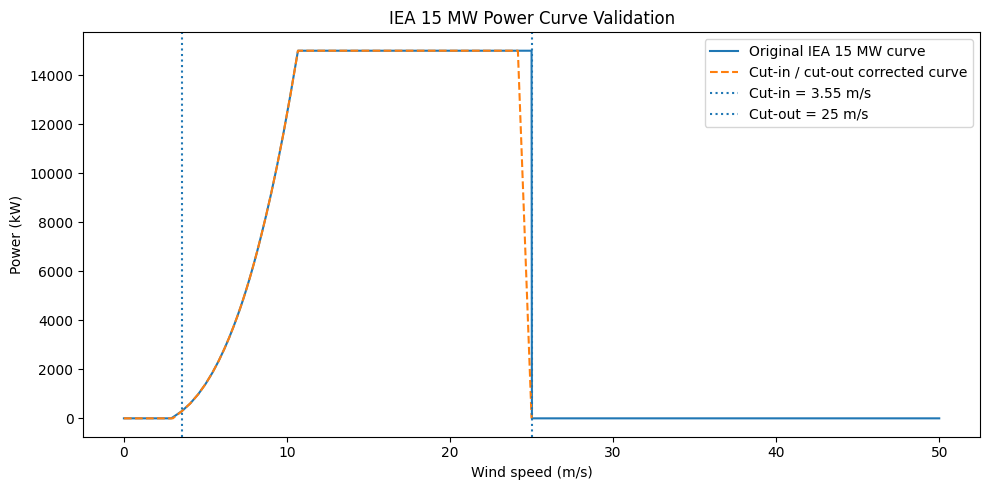

In [120]:
import matplotlib.pyplot as plt

# Compare original and corrected power curves
original_curve = (
    iea_15mw[["wind_speed_ms", "power_kw"]]
    .sort_values("wind_speed_ms")
)

corrected_curve = (
    curve_check[["wind_speed_ms", "power_kw"]]
    .sort_values("wind_speed_ms")
)

plt.figure(figsize=(10, 5))

plt.plot(
    original_curve["wind_speed_ms"],
    original_curve["power_kw"],
    label="Original IEA 15 MW curve"
)

plt.plot(
    corrected_curve["wind_speed_ms"],
    corrected_curve["power_kw"],
    linestyle="--",
    label="Cut-in / cut-out corrected curve"
)

plt.axvline(
    cut_in,
    linestyle=":",
    label=f"Cut-in = {cut_in:.2f} m/s"
)

plt.axvline(
    cut_out,
    linestyle=":",
    label=f"Cut-out = {cut_out:.0f} m/s"
)

plt.xlabel("Wind speed (m/s)")
plt.ylabel("Power (kW)")
plt.title("IEA 15 MW Power Curve Validation")
plt.legend()
plt.grid(False)
plt.tight_layout()
plt.show()

In [121]:
# Create a clean model-results dataframe
df_wind_model = pd.DataFrame({
    "timestamp": pd.to_datetime(df["Date/Time"]),
    "wind_speed_100m_ms": df["ERA5_ws100"].to_numpy(),
    "wind_speed_hub_ms": df["Wind_Speed_Hub_150m"].to_numpy(),
    "air_density_kgm3": df["Air_Density_Hub"].to_numpy(),
    "power_mw": df["IEA15MW_Checked_MW"].to_numpy()
})

df_wind_model = df_wind_model.sort_values("timestamp").reset_index(drop=True)

display(df_wind_model.head())
display(df_wind_model.tail())

print("Rows:", len(df_wind_model))
print("Missing values:\n", df_wind_model.isna().sum())
print("Duplicate timestamps:", df_wind_model["timestamp"].duplicated().sum())
print(
    "Time interval:",
    df_wind_model["timestamp"].diff().dropna().value_counts().head()
)

,timestamp,wind_speed_100m_ms,wind_speed_hub_ms,air_density_kgm3,power_mw
0,2018-01-01 00:00:00,5.263079,5.526154,1.222900,1.982099
1,2018-01-01 00:10:00,5.685947,5.970160,1.265029,2.657495
2,2018-01-01 00:20:00,5.239275,5.501160,1.241635,1.985798
3,2018-01-01 00:30:00,5.685947,5.970160,1.265029,2.657495
4,2018-01-01 00:40:00,5.531726,5.808230,1.174375,2.237641


,timestamp,wind_speed_100m_ms,wind_speed_hub_ms,air_density_kgm3,power_mw
50525,2018-12-31 23:10:00,11.552056,12.129486,1.207451,15.000000
50526,2018-12-31 23:20:00,7.271863,7.635348,1.234617,5.587475
50527,2018-12-31 23:30:00,8.497058,8.921784,1.245466,9.048397
50528,2018-12-31 23:40:00,9.402127,9.872093,1.255255,12.399886
50529,2018-12-31 23:50:00,9.998500,10.498275,1.213673,14.117272


Rows: 50530
Missing values:
 timestamp             0
wind_speed_100m_ms    0
wind_speed_hub_ms     0
air_density_kgm3      0
power_mw              0
dtype: int64
Duplicate timestamps: 0
Time interval: timestamp
0 days 00:10:00    50497
0 days 00:20:00       11
0 days 00:40:00        2
0 days 03:00:00        1
4 days 08:20:00        1
Name: count, dtype: int64


In [122]:
# Calculate energy for each 10-minute interval
df_wind_model["energy_mwh"] = (
    df_wind_model["power_mw"] * (10 / 60)
)

# Annual summary
annual_energy_mwh = df_wind_model["energy_mwh"].sum()
mean_power_mw = df_wind_model["power_mw"].mean()
rated_power_mw = 15.0

capacity_factor = mean_power_mw / rated_power_mw

print(f"Annual energy: {annual_energy_mwh:,.2f} MWh")
print(f"Annual energy: {annual_energy_mwh / 1000:,.2f} GWh")
print(f"Mean power: {mean_power_mw:.3f} MW")
print(f"Capacity factor: {capacity_factor:.2%}")

Annual energy: 55,340.44 MWh
Annual energy: 55.34 GWh
Mean power: 6.571 MW
Capacity factor: 43.81%


In [123]:
import pandas as pd
import numpy as np

df_wind_model = df_wind_model.sort_values("timestamp").reset_index(drop=True)

# Actual time between consecutive observations
df_wind_model["interval_minutes"] = (
    df_wind_model["timestamp"].diff().dt.total_seconds() / 60
)

# Find all intervals that are not 10 minutes
irregular_intervals = df_wind_model.loc[
    df_wind_model["interval_minutes"].notna()
    & (df_wind_model["interval_minutes"] != 10),
    ["timestamp", "interval_minutes"]
]

print("Irregular intervals:", len(irregular_intervals))
display(irregular_intervals)

# Basic density check
print("\nAir density summary:")
display(df_wind_model["air_density_kgm3"].describe().round(4))

# Coverage check
print("\nFirst timestamp:", df_wind_model["timestamp"].min())
print("Last timestamp:", df_wind_model["timestamp"].max())
print("Expected 10-minute intervals across the year:",
      int((df_wind_model["timestamp"].max()
           - df_wind_model["timestamp"].min()).total_seconds() / 600))

Irregular intervals: 32


,timestamp,interval_minutes
491,2018-01-04 12:40:00,180.0
768,2018-01-06 11:30:00,50.0
1577,2018-01-12 02:30:00,20.0
3617,2018-01-30 14:40:00,6260.0
9188,2018-03-10 07:20:00,20.0
12866,2018-04-04 20:30:00,20.0
14647,2018-04-17 06:50:00,100.0
14710,2018-04-17 18:10:00,60.0
17116,2018-05-04 13:10:00,130.0
20369,2018-05-27 03:50:00,40.0



Air density summary:


count    50530.0000
mean         1.1402
std          0.0809
min          0.8581
25%          1.0898
50%          1.1623
75%          1.1994
max          1.3416
Name: air_density_kgm3, dtype: float64


First timestamp: 2018-01-01 00:00:00
Last timestamp: 2018-12-31 23:50:00
Expected 10-minute intervals across the year: 52559


In [124]:
import numpy as np
import pandas as pd

df_wind_model = (
    df_wind_model.sort_values("timestamp")
    .reset_index(drop=True)
    .copy()
)

# Time to the next observation
df_wind_model["next_interval_min"] = (
    df_wind_model["timestamp"].shift(-1)
    .sub(df_wind_model["timestamp"])
    .dt.total_seconds()
    .div(60)
)

# Mark intervals that are exactly 10 minutes long
df_wind_model["valid_10min_interval"] = (
    df_wind_model["next_interval_min"].eq(10)
)

# Energy for valid intervals only
df_wind_model["energy_mwh_valid"] = np.where(
    df_wind_model["valid_10min_interval"],
    df_wind_model["power_mw"] / 6,
    0.0
)

# The last observation is at 23:50, so it represents the
# final 10-minute interval to midnight, assuming regular sampling.
df_wind_model.loc[
    df_wind_model.index[-1], "energy_mwh_valid"
] = df_wind_model["power_mw"].iloc[-1] / 6

# Summary
expected_intervals = 365 * 24 * 6
valid_intervals = int(
    df_wind_model["valid_10min_interval"].sum() + 1
)

observed_energy_mwh = df_wind_model["energy_mwh_valid"].sum()
coverage = valid_intervals / expected_intervals

print(f"Expected 10-minute intervals: {expected_intervals:,}")
print(f"Intervals included: {valid_intervals:,}")
print(f"Time coverage: {coverage:.2%}")
print(f"Energy over included intervals: {observed_energy_mwh:,.2f} MWh")
print(f"Energy over included intervals: {observed_energy_mwh / 1000:,.2f} GWh")

Expected 10-minute intervals: 52,560
Intervals included: 50,498
Time coverage: 96.08%
Energy over included intervals: 55,323.70 MWh
Energy over included intervals: 55.32 GWh


In [125]:
# Add season based on timestamp month
month = df_wind_model["timestamp"].dt.month

df_wind_model["Season"] = np.select(
    [
        month.isin([12, 1, 2]),
        month.isin([3, 4, 5]),
        month.isin([6, 7, 8]),
        month.isin([9, 10, 11])
    ],
    ["Winter", "Spring", "Summer", "Autumn"],
    default="Unknown"
)

# Seasonal energy and coverage
seasonal_summary = (
    df_wind_model.groupby("Season")
    .agg(
        Observations=("power_mw", "size"),
        Mean_Power_MW=("power_mw", "mean"),
        Energy_MWh=("energy_mwh_valid", "sum"),
        Valid_Intervals=("valid_10min_interval", "sum")
    )
    .reindex(["Winter", "Spring", "Summer", "Autumn"])
)

seasonal_summary["Energy_GWh"] = seasonal_summary["Energy_MWh"] / 1000

display(seasonal_summary.round(3))

,Observations,Mean_Power_MW,Energy_MWh,Valid_Intervals,Energy_GWh
Season,,,,,
Winter,12296,7.287,14928.178,12288,14.928
Spring,13217,5.851,12884.649,13211,12.885
Summer,13134,5.757,12597.095,13124,12.597
Autumn,11883,7.531,14913.780,11874,14.914


In [126]:
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prepare ML features
feature_cols = [
    "ERA5_ws100",
    "Temperature",
    "Pressure",
    "Wind_Direction(rad)"
]

target_col = "LV ActivePower (kW)"

# Keep only required columns and remove missing rows
ml_data = df[feature_cols + [target_col]].copy()
ml_data = ml_data.replace([np.inf, -np.inf], np.nan).dropna()

X = ml_data[feature_cols]
y = ml_data[target_col]

# Chronological split: first 80% train, last 20% test
split_idx = int(len(ml_data) * 0.8)

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]
y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

# Train model
rf_model = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predict
y_pred = rf_model.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Training rows: {len(X_train):,}")
print(f"Testing rows: {len(X_test):,}")
print(f"MAE: {mae:.2f} kW")
print(f"RMSE: {rmse:.2f} kW")
print(f"R²: {r2:.4f}")

Training rows: 40,424
Testing rows: 10,106
MAE: 312.19 kW
RMSE: 631.24 kW
R²: 0.7788


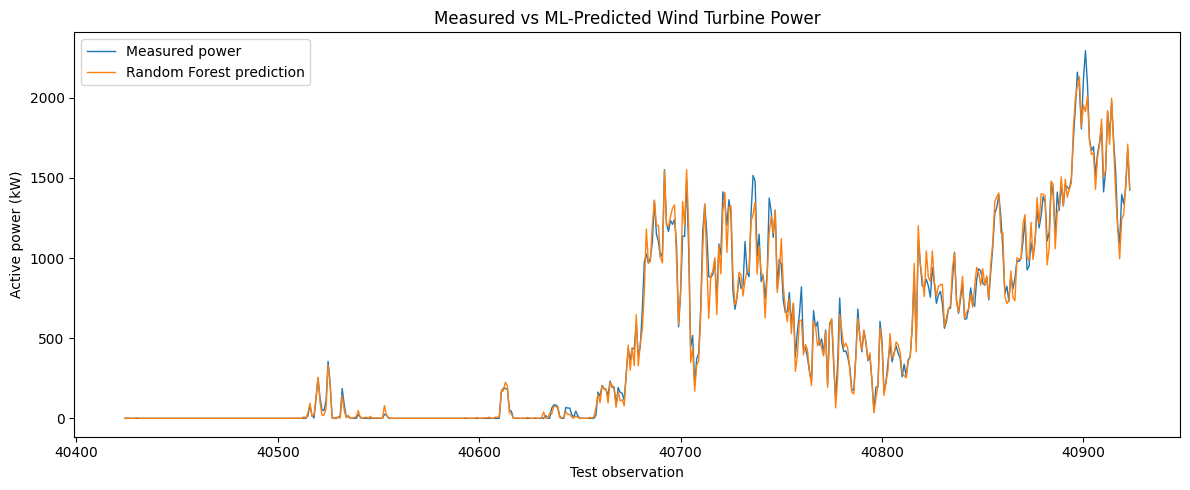

In [127]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    y_test.index[:500],
    y_test.iloc[:500].values,
    label="Measured power",
    linewidth=1
)

plt.plot(
    y_test.index[:500],
    y_pred[:500],
    label="Random Forest prediction",
    linewidth=1
)

plt.xlabel("Test observation")
plt.ylabel("Active power (kW)")
plt.title("Measured vs ML-Predicted Wind Turbine Power")
plt.legend()
plt.tight_layout()
plt.show()

In [128]:
# Compare measured and predicted power
comparison = pd.DataFrame({
    "Measured_kW": y_test,
    "Predicted_kW": y_pred
})

comparison["Error_kW"] = (
    comparison["Measured_kW"] - comparison["Predicted_kW"]
)

comparison["Absolute_Error_kW"] = comparison["Error_kW"].abs()

display(comparison.head(10).round(2))

print(f"MAE: {comparison['Absolute_Error_kW'].mean():.2f} kW")
print(f"RMSE: {np.sqrt((comparison['Error_kW']**2).mean()):.2f} kW")
print(f"Maximum absolute error: {comparison['Absolute_Error_kW'].max():.2f} kW")

,Measured_kW,Predicted_kW,Error_kW,Absolute_Error_kW
40424,0.0,0.59,-0.59,0.59
40425,0.0,0.08,-0.08,0.08
40426,0.0,1.60,-1.60,1.60
40427,0.0,0.17,-0.17,0.17
40428,0.0,0.00,-0.00,0.00
40429,0.0,0.20,-0.20,0.20
40430,0.0,3.38,-3.38,3.38
40431,0.0,0.08,-0.08,0.08
40432,0.0,0.09,-0.09,0.09
40433,0.0,0.00,-0.00,0.00


MAE: 312.19 kW
RMSE: 631.24 kW
Maximum absolute error: 3567.98 kW


In [129]:
comparison = pd.DataFrame({
    "Measured_kW": np.asarray(y_test),
    "Predicted_kW": np.asarray(y_pred)
})

comparison["Error_kW"] = (
    comparison["Measured_kW"] - comparison["Predicted_kW"]
)
comparison["Absolute_Error_kW"] = comparison["Error_kW"].abs()

display(comparison.head(10).round(2))

print("\nModel performance")
print(f"MAE:  {mean_absolute_error(y_test, y_pred):.2f} kW")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.2f} kW")
print(f"R²:   {r2_score(y_test, y_pred):.4f}")
print(f"Measured power range: {y_test.min():.2f} to {y_test.max():.2f} kW")

,Measured_kW,Predicted_kW,Error_kW,Absolute_Error_kW
0,0.0,0.59,-0.59,0.59
1,0.0,0.08,-0.08,0.08
2,0.0,1.60,-1.60,1.60
3,0.0,0.17,-0.17,0.17
4,0.0,0.00,-0.00,0.00
5,0.0,0.20,-0.20,0.20
6,0.0,3.38,-3.38,3.38
7,0.0,0.08,-0.08,0.08
8,0.0,0.09,-0.09,0.09
9,0.0,0.00,-0.00,0.00



Model performance
MAE:  312.19 kW
RMSE: 631.24 kW
R²:   0.7788
Measured power range: -1.08 to 3604.48 kW


In [130]:

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Train a single Decision Tree
dt_model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=20,
    random_state=42
)

dt_model.fit(X_train, y_train)

# Predict on the same test set
dt_pred = dt_model.predict(X_test)

# Compare both models
results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "MAE_kW": [
        mean_absolute_error(y_test, dt_pred),
        mean_absolute_error(y_test, y_pred)
    ],
    "RMSE_kW": [
        np.sqrt(mean_squared_error(y_test, dt_pred)),
        np.sqrt(mean_squared_error(y_test, y_pred))
    ],
    "R2": [
        r2_score(y_test, dt_pred),
        r2_score(y_test, y_pred)
    ]
})

display(results.round(4))


,Model,MAE_kW,RMSE_kW,R2
0,Decision Tree,312.8688,652.9941,0.7633
1,Random Forest,312.1883,631.2450,0.7788


In [132]:

import numpy as np
import pandas as pd

R_air = 287.05  # J/(kg·K)

# Calculate air density using the ideal gas law
df["Air_Density_Calculated"] = (
    df["Pressure"] / (R_air * df["Temperature"])
)

# Compare against an existing density column, if available
print("Calculated air density:")
display(df["Air_Density_Calculated"].describe().to_frame())

if "air_density" in df.columns:
    comparison_density = pd.DataFrame({
        "Existing": df["air_density"],
        "Calculated": df["Air_Density_Calculated"]
    })
    comparison_density["Difference"] = (
        comparison_density["Calculated"] - comparison_density["Existing"]
    )

    display(comparison_density.head().round(4))
    print(
        "Mean absolute density difference:",
        comparison_density["Difference"].abs().mean()
    )

Calculated air density:


,Air_Density_Calculated
count,50530.000000
mean,1.159011
std,0.080655
min,0.877835
25%,1.108623
50%,1.180645
75%,1.218041
max,1.361696


,Existing,Calculated,Difference
0,1.2330,1.2418,0.0088
1,1.2754,1.2843,0.0090
2,1.2518,1.2607,0.0088
3,1.2754,1.2843,0.0090
4,1.1846,1.1934,0.0088


Mean absolute density difference: 0.008757155


In [133]:

density_check = pd.DataFrame({
    "Existing": df["air_density"],
    "Calculated": df["Air_Density_Calculated"]
})

density_check["Difference"] = (
    density_check["Calculated"] - density_check["Existing"]
)

print("Existing mean:", density_check["Existing"].mean())
print("Calculated mean:", density_check["Calculated"].mean())
print("Mean signed difference:", density_check["Difference"].mean())
print("Mean absolute difference:", density_check["Difference"].abs().mean())
print("Minimum difference:", density_check["Difference"].min())
print("Maximum difference:", density_check["Difference"].max())


Existing mean: 1.1502538
Calculated mean: 1.1590106
Mean signed difference: 0.008757155
Mean absolute difference: 0.008757155
Minimum difference: 0.008115053176879883
Maximum difference: 0.01027989387512207


In [134]:
print("Temperature:")
print(df["Temperature"].describe())

print("\nPressure:")
print(df["Pressure"].describe())

print("\nFirst 5 input values:")
display(
    df[["Temperature", "Pressure", "air_density",
        "Air_Density_Calculated"]].head().round(5)
)

Temperature:
count    50530.000000
mean       289.648041
std          8.651648
min        255.323990
25%        283.835480
50%        290.049988
75%        296.199982
max        317.250000
Name: Temperature, dtype: float64

Pressure:
count     50530.000000
mean      96362.898438
std        7160.528320
min       69939.828125
25%       91873.460938
50%      100570.000000
75%      101410.000000
max      103360.000000
Name: Pressure, dtype: float64

First 5 input values:


,Temperature,Pressure,air_density,Air_Density_Calculated
0,284.750000,101500.000000,1.23301,1.24178
1,276.372986,101890.000000,1.27537,1.28434
2,281.449982,101850.000000,1.25183,1.26067
3,276.372986,101890.000000,1.27537,1.28434
4,285.299988,97732.242188,1.18455,1.19338


In [135]:

# Infer the effective gas constant behind the existing density
df["R_effective_existing"] = (
    df["Pressure"] /
    (df["air_density"] * df["Temperature"])
)

print("Effective gas constant, existing density:")
display(df["R_effective_existing"].describe().to_frame())

print("\nExpected dry-air gas constant: approximately 287.05 J/(kg·K)")


Effective gas constant, existing density:


,R_effective_existing
count,50530.000000
mean,289.249725
std,0.229989
min,289.027100
25%,289.103455
50%,289.131378
75%,289.354485
max,290.201263



Expected dry-air gas constant: approximately 287.05 J/(kg·K)


In [131]:

# Correlation of available features with measured power
target = df["LV ActivePower (kW)"]

candidate_features = [
    "ERA5_ws100",
    "Wind Speed (m/s)",
    "Temperature",
    "Pressure"
]

available_features = [
    col for col in candidate_features if col in df.columns
]

correlations = (
    df[available_features]
    .join(target.rename("Measured_Power_kW"))
    .corr(numeric_only=True)["Measured_Power_kW"]
    .drop("Measured_Power_kW")
    .sort_values(key=abs, ascending=False)
)

display(correlations.to_frame("Correlation_with_Measured_Power").round(3))

,Correlation_with_Measured_Power
Wind Speed (m/s),0.913
ERA5_ws100,0.913
Pressure,0.412
Temperature,0.127


In [136]:

# Correlation of available features with measured power
target = df["LV ActivePower (kW)"]

# Physics-based air density
R_air = 287.05
df["Air_Density_Calculated"] = (
    df["Pressure"] / (R_air * df["Temperature"])
)

candidate_features = [
    "ERA5_ws100",
    "Wind Speed (m/s)",
    "Temperature",
    "Pressure",
    "Air_Density_Calculated"
]

available_features = [
    col for col in candidate_features if col in df.columns
]

correlations = (
    df[available_features]
    .join(target.rename("Measured_Power_kW"))
    .corr(numeric_only=True)["Measured_Power_kW"]
    .drop("Measured_Power_kW")
    .sort_values(key=abs, ascending=False)
)

display(
    correlations.to_frame("Correlation_with_Measured_Power").round(3)
)

,Correlation_with_Measured_Power
Wind Speed (m/s),0.913
ERA5_ws100,0.913
Pressure,0.412
Air_Density_Calculated,0.389
Temperature,0.127


In [137]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

target_col = "LV ActivePower (kW)"

base_features = [
    "ERA5_ws100",
    "Temperature",
    "Pressure",
    "Wind_Direction(rad)"
]

density_features = base_features + ["Air_Density_Calculated"]

def evaluate_rf(features, label):
    data = df[features + [target_col]].copy()
    data = data.replace([np.inf, -np.inf], np.nan).dropna()

    X = data[features]
    y = data[target_col]

    split = int(len(data) * 0.8)
    X_train, X_test = X.iloc[:split], X.iloc[split:]
    y_train, y_test = y.iloc[:split], y.iloc[split:]

    model = RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    return {
        "Model": label,
        "MAE_kW": mean_absolute_error(y_test, pred),
        "RMSE_kW": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    }

results_density = pd.DataFrame([
    evaluate_rf(base_features, "Without density"),
    evaluate_rf(density_features, "With density")
])

display(results_density.round(4))

,Model,MAE_kW,RMSE_kW,R2
0,Without density,312.1883,631.2450,0.7788
1,With density,316.6482,646.5413,0.7679


In [138]:

# Check whether the two wind-speed columns contain different information

wind_comparison = df[
    ["Wind Speed (m/s)", "ERA5_ws100"]
].corr()

display(wind_comparison.round(5))

print(
    "Mean absolute difference:",
    (
        df["Wind Speed (m/s)"] - df["ERA5_ws100"]
    ).abs().mean()
)

print(
    "Correlation between wind speeds:",
    df["Wind Speed (m/s)"].corr(df["ERA5_ws100"])
)


,Wind Speed (m/s),ERA5_ws100
Wind Speed (m/s),1.00000,0.98649
ERA5_ws100,0.98649,1.00000


Mean absolute difference: 0.222303531586519
Correlation between wind speeds: 0.9864917633914108


In [139]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Define features and target
target_col = "LV ActivePower (kW)"

common_features = [
    "Temperature",
    "Pressure",
    "Wind_Direction(rad)"
]

feature_sets = {
    "A: Original wind speed": [
        "Wind Speed (m/s)"
    ] + common_features,

    "B: ERA5 wind speed": [
        "ERA5_ws100"
    ] + common_features,

    "C: Both wind speeds": [
        "Wind Speed (m/s)",
        "ERA5_ws100"
    ] + common_features
}

# 2. Sort chronologically
data = df.copy()
data["Date/Time"] = pd.to_datetime(data["Date/Time"])
data = data.sort_values("Date/Time").reset_index(drop=True)

# 3. Keep rows with valid values in every feature used
all_features = list(dict.fromkeys(
    feature for features in feature_sets.values()
    for feature in features
))

required_cols = all_features + [target_col]
data[required_cols] = data[required_cols].replace(
    [np.inf, -np.inf], np.nan
)
data = data.dropna(subset=required_cols).reset_index(drop=True)

# 4. Use the same chronological 80/20 split for every model
split_idx = int(len(data) * 0.8)

train = data.iloc[:split_idx]
test = data.iloc[split_idx:]

y_train = train[target_col]
y_test = test[target_col]

# 5. Train and evaluate the three models
results = []

for model_name, features in feature_sets.items():
    model = RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )

    model.fit(train[features], y_train)
    predictions = model.predict(test[features])

    results.append({
        "Model": model_name,
        "Features": len(features),
        "MAE_kW": mean_absolute_error(y_test, predictions),
        "RMSE_kW": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values("RMSE_kW")
display(results_df.round(4))

,Model,Features,MAE_kW,RMSE_kW,R2
0,A: Original wind speed,4,259.8319,560.9539,0.8253
2,C: Both wind speeds,5,274.5828,598.8688,0.8009
1,B: ERA5 wind speed,4,312.1883,631.2450,0.7788


In [141]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Define features and target
feature_cols = [
    "Wind Speed (m/s)",
    "Temperature",
    "Pressure",
    "Wind_Direction(rad)"
]

target_col = "LV ActivePower (kW)"

# 2. Prepare data and sort chronologically
data = df.copy()
data["Date/Time"] = pd.to_datetime(data["Date/Time"])

data = data.sort_values("Date/Time").reset_index(drop=True)

# 3. Remove infinite and missing values
required_cols = feature_cols + [target_col]

data[required_cols] = data[required_cols].replace(
    [np.inf, -np.inf], np.nan
)

data = data.dropna(subset=required_cols).reset_index(drop=True)

# 4. Separate features (X) and target (y)
X = data[feature_cols]
y = data[target_col]

# 5. Chronological 80/20 train-test split
split_index = int(len(data) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training period:", data["Date/Time"].iloc[0],
      "to", data["Date/Time"].iloc[split_index - 1])
print("Testing period:", data["Date/Time"].iloc[split_index],
      "to", data["Date/Time"].iloc[-1])

# 6. Train Random Forest
model = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# 7. Predict on unseen test data
y_pred = model.predict(X_test)

# 8. Evaluate model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

results = pd.DataFrame({
    "Metric": ["MAE (kW)", "RMSE (kW)", "R²"],
    "Value": [mae, rmse, r2]
})

display(results.round(4))

# 9. Compare actual and predicted power
comparison = pd.DataFrame({
    "Date/Time": data["Date/Time"].iloc[split_index:].to_numpy(),
    "Measured_kW": y_test.to_numpy(),
    "Predicted_kW": y_pred
})

comparison["Error_kW"] = (
    comparison["Measured_kW"] - comparison["Predicted_kW"]
)

display(comparison.head(10))

Training samples: 40424
Testing samples: 10106
Training period: 2018-01-01 00:00:00 to 2018-10-18 22:30:00
Testing period: 2018-10-18 22:40:00 to 2018-12-31 23:50:00


,Metric,Value
0,MAE (kW),259.8319
1,RMSE (kW),560.9539
2,R²,0.8253


,Date/Time,Measured_kW,Predicted_kW,Error_kW
0,2018-10-18 22:40:00,0.0,0.043984,-0.043984
1,2018-10-18 22:50:00,0.0,0.063625,-0.063625
2,2018-10-18 23:00:00,0.0,1.295117,-1.295117
3,2018-10-18 23:10:00,0.0,0.213262,-0.213262
4,2018-10-18 23:20:00,0.0,0.000000,0.000000
5,2018-10-18 23:30:00,0.0,0.192130,-0.192130
6,2018-10-18 23:40:00,0.0,3.425974,-3.425974
7,2018-10-18 23:50:00,0.0,0.368156,-0.368156
8,2018-10-19 00:00:00,0.0,0.121295,-0.121295
9,2018-10-19 00:10:00,0.0,0.000000,0.000000


In [142]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Features and target
feature_cols = [
    "Wind Speed (m/s)",
    "Temperature",
    "Pressure",
    "Wind_Direction(rad)"
]

target_col = "LV ActivePower (kW)"

# 2. Prepare the data
data = df.copy()

required_cols = feature_cols + [target_col]

data[required_cols] = data[required_cols].replace(
    [np.inf, -np.inf], np.nan
)

data = data.dropna(subset=required_cols).reset_index(drop=True)

X = data[feature_cols]
y = data[target_col]

# 3. Randomly shuffle and split: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Check the date coverage in both sets
timestamps = pd.to_datetime(data["Date/Time"])

print(
    "Training period:",
    timestamps.loc[X_train.index].min(),
    "to",
    timestamps.loc[X_train.index].max()
)

print(
    "Testing period:",
    timestamps.loc[X_test.index].min(),
    "to",
    timestamps.loc[X_test.index].max()
)

# 4. Train Random Forest
model = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# 5. Predictions
y_pred = model.predict(X_test)

# 6. Evaluation
results = pd.DataFrame({
    "Metric": ["MAE (kW)", "RMSE (kW)", "R²"],
    "Value": [
        mean_absolute_error(y_test, y_pred),
        np.sqrt(mean_squared_error(y_test, y_pred)),
        r2_score(y_test, y_pred)
    ]
})

display(results.round(4))

# 7. Actual vs predicted power
comparison = pd.DataFrame({
    "Measured_kW": y_test.to_numpy(),
    "Predicted_kW": y_pred
})

comparison["Error_kW"] = (
    comparison["Measured_kW"] - comparison["Predicted_kW"]
)

display(comparison.head(10))

Training samples: 40424
Testing samples: 10106
Training period: 2018-01-01 00:00:00 to 2018-12-31 23:50:00
Testing period: 2018-01-01 00:40:00 to 2018-12-31 22:20:00


,Metric,Value
0,MAE (kW),118.6911
1,RMSE (kW),303.7818
2,R²,0.9459


,Measured_kW,Predicted_kW,Error_kW
0,3348.910889,3102.784965,246.125923
1,2647.506104,2685.893613,-38.387510
2,0.000000,505.494017,-505.494017
3,1334.573975,1450.414869,-115.840894
4,533.002808,497.373567,35.629240
5,2496.370117,2717.219501,-220.849384
6,1071.803955,1054.630866,17.173089
7,3587.481934,3489.787834,97.694099
8,450.298004,503.353855,-53.055851
9,3387.311035,3286.220680,101.090355


In [143]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Recover the timestamps corresponding to the shuffled test rows
test_dates = pd.to_datetime(
    data.loc[X_test.index, "Date/Time"]
)

season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

season_results = pd.DataFrame({
    "Date/Time": test_dates.to_numpy(),
    "Measured_kW": y_test.to_numpy(),
    "Predicted_kW": y_pred
})

season_results["Season"] = (
    pd.to_datetime(season_results["Date/Time"])
    .dt.month.map(season_map)
)

rows = []

for season, group in season_results.groupby("Season"):
    rows.append({
        "Season": season,
        "Samples": len(group),
        "MAE_kW": mean_absolute_error(
            group["Measured_kW"], group["Predicted_kW"]
        ),
        "RMSE_kW": np.sqrt(mean_squared_error(
            group["Measured_kW"], group["Predicted_kW"]
        )),
        "R2": r2_score(
            group["Measured_kW"], group["Predicted_kW"]
        )
    })

season_metrics = pd.DataFrame(rows)

season_order = ["Winter", "Spring", "Summer", "Autumn"]
season_metrics["Season"] = pd.Categorical(
    season_metrics["Season"],
    categories=season_order,
    ordered=True
)

season_metrics = season_metrics.sort_values("Season")
display(season_metrics.round(4))

,Season,Samples,MAE_kW,RMSE_kW,R2
3,Winter,2463,238.2596,490.0092,0.8804
1,Spring,2619,95.9698,260.6618,0.9611
2,Summer,2706,54.4069,147.4315,0.9844
0,Autumn,2318,92.3593,212.2871,0.9721


In [144]:

# Summarize measured power and prediction errors by season

season_results["Absolute_Error_kW"] = (
    season_results["Measured_kW"]
    - season_results["Predicted_kW"]
).abs()

season_results["Month"] = (
    pd.to_datetime(season_results["Date/Time"]).dt.month
)

power_summary = season_results.groupby("Season").agg(
    Samples=("Measured_kW", "size"),
    Mean_Power_kW=("Measured_kW", "mean"),
    Median_Power_kW=("Measured_kW", "median"),
    Min_Power_kW=("Measured_kW", "min"),
    Max_Power_kW=("Measured_kW", "max"),
    Zero_or_Near_Zero_Count=(
        "Measured_kW",
        lambda s: (s <= 50).sum()
    ),
    Mean_Absolute_Error_kW=("Absolute_Error_kW", "mean")
)

display(power_summary.round(2))

,Samples,Mean_Power_kW,Median_Power_kW,Min_Power_kW,Max_Power_kW,Zero_or_Near_Zero_Count,Mean_Absolute_Error_kW
Season,,,,,,,
Autumn,2318,1525.46,1235.35,-0.18,3604.37,337,92.36
Spring,2619,1186.97,547.84,-0.52,3604.53,791,95.97
Summer,2706,1163.21,733.87,-0.41,3604.56,588,54.41
Winter,2463,1329.47,724.98,-2.47,3604.56,828,238.26


In [146]:
# Compare wind-speed distributions by season

wind_col = "Wind Speed (m/s)"

season_results["Wind_Speed"] = data.loc[
    X_test.index, wind_col
].to_numpy()

wind_summary = season_results.groupby(
    "Season", observed=True
).agg(
    Samples=("Wind_Speed", "size"),
    Mean_Wind_Speed=("Wind_Speed", "mean"),
    Median_Wind_Speed=("Wind_Speed", "median"),
    Wind_Speed_Std=("Wind_Speed", "std"),
    Min_Wind_Speed=("Wind_Speed", "min"),
    Max_Wind_Speed=("Wind_Speed", "max")
).reset_index()

display(wind_summary.round(3))

,Season,Samples,Mean_Wind_Speed,Median_Wind_Speed,Wind_Speed_Std,Min_Wind_Speed,Max_Wind_Speed
0,Autumn,2318,8.002,7.695,3.798,0.442,20.397
1,Spring,2619,7.074,6.223,4.403,0.316,21.329
2,Summer,2706,6.903,6.732,3.508,0.315,17.653
3,Winter,2463,8.197,7.730,4.764,0.400,24.587
